<a href="https://colab.research.google.com/github/buketckr/my-new-repo/blob/main/Assignment1_b_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EE48009 — Assignment 1
## Channel Estimation and Pilot Overhead with Sionna


In [ ]:
%pip install -q "sionna==2.2.0"

In [ ]:
!pip install --force-reinstall "numpy<2.3"

  Using cached numpy-2.2.6-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (62 kB)
Using cached numpy-2.2.6-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (16.5 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.2.6
    Uninstalling numpy-2.2.6:
      Successfully uninstalled numpy-2.2.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.21.0 requires h5py<3.15.0,>=3.11.0, but you have h5py 3.16.0 which is incompatible.



## Step 1: Scenario Selection

For this assignment, we selected the built-in San Francisco scene provided by Sionna RT. The environment contains an urban layout with multiple buildings, streets, and obstacles that can affect wireless signal propagation.

The urban layout provides an useful environment for examining how multipath propagation and doppler shifts affect channel estimation and pilot overhead.

The presence of buildings and streets can create both Los and NLoS propagation paths. Therefore multipath propagation can produce frequency selective channels. The delay spread is expected to vary across UE locations depending on surrounding buildings and whether direct propagation paths are available.

UE mobility will also produce Doppler shifts, causing the wireless channel to change over time and allowing us to study the impact of time selectivity on channel estimation.


In [ ]:
import sionna
import numpy as np
from sionna.rt import load_scene, PlanarArray, Transmitter, Receiver, Camera, \
                      PathSolver, RadioMapSolver, subcarrier_frequencies

scene = load_scene(sionna.rt.scene.san_francisco)
scene.frequency = 3.5e9

Scene center: [102.69644165  -4.18571472  85.31410217]
Scene dimensions: [1221.70318604  927.69338989  170.62820435]


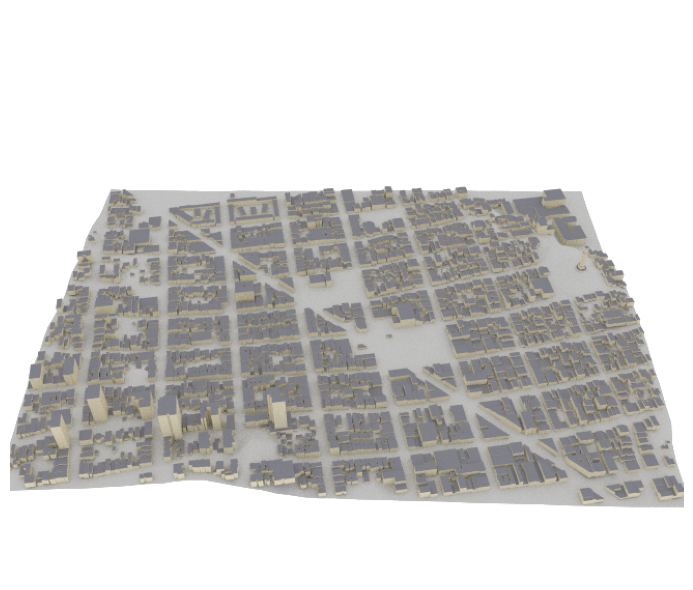

In [ ]:
#Obtain the bounding box for the scene
bbox = scene.mi_scene.bbox()

#Minimum and maximum coordinates
p_min = np.array(bbox.min, dtype=float)
p_max = np.array(bbox.max, dtype=float)

#Calculate the scene center and dimensions
center = (p_min + p_max) / 2
size = p_max - p_min

print("Scene center:", center)
print("Scene dimensions:", size)

#Automatically position the camera
camera_position = center + np.array([0.0, -1 * max(size[0], size[1]), 1 * max(size[0], size[1])])

auto_cam = Camera(
    position=camera_position.tolist(),
    look_at=center.tolist()
)

scene.render(
    camera=auto_cam,
    resolution=[650, 550],
    num_samples=128
);


## Step 2 — Base Station and UE Configuration

### 2.1 Antenna Array Configuration

In [ ]:

from sionna.rt import PlanarArray

#Creating a single transmit antenna of UE
scene.tx_array = PlanarArray(
    num_rows=1,
    num_cols=1,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="iso",
    polarization="V"
)

#BS: M x M receive antenna array
M = 1  #M will take values 1,2 and 4.

scene.rx_array = PlanarArray(
    num_rows=M,
    num_cols=M,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="tr38901",
    polarization="V"
)

print(f"UE antennas: 1")
print(f"BS array: {M} x {M}")
print(f"BS antenna elements: {M**2}")


UE antennas: 1
BS array: 1 x 1
BS antenna elements: 1


### 2.2 Base Station Placement

The base station is positioned on the Coit Tower in the San Francisco scene. This elevated location was selected using Blender to provide coverage over the surrounding urban environment.


In [ ]:

from sionna.rt import Transmitter, Receiver

bs_position = [614.7, 74.79, 150.8]

bs = Receiver(
    name="bs",
    position=bs_position
)

scene.add(bs)

print("BS position:", bs.position)



BS position: [[614.7, 74.79, 150.8]]


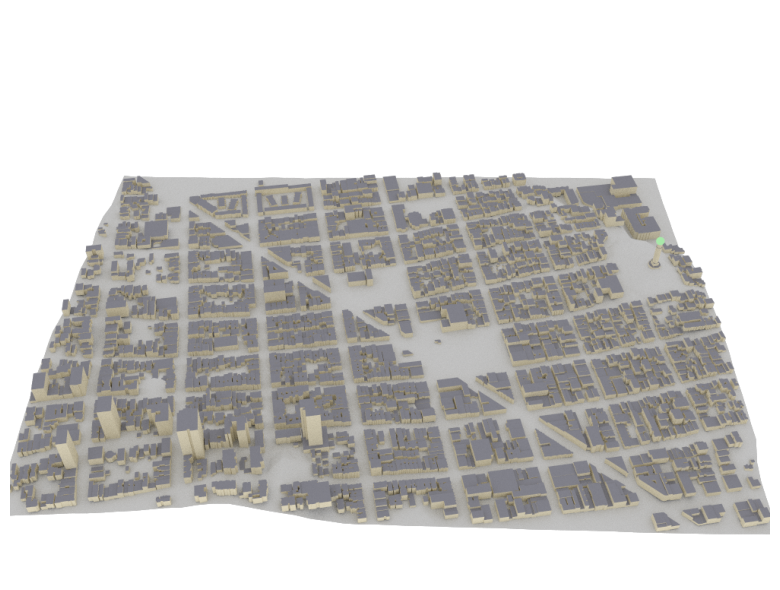

In [ ]:

#This cell visualises the BS.

scene.render(
    camera=auto_cam,
    show_devices=True,
    resolution=[1000, 750],
    num_samples=128
);


##STEP 3.1 Define UE coverage region

In [ ]:
import numpy as np

#200x200 region
center_x = 465.0
center_y = 95.0

region_size = 200.0
grid_spacing = 10.0

rotation_deg = 10.0
rotation_rad = np.deg2rad(rotation_deg)

ue_region_center = [center_x, center_y]

print("Region center:", ue_region_center)
print("Dimensions:", region_size, "x", region_size, "m")
print("Rotation:", rotation_deg, "degrees")



Region center: [465.0, 95.0]
Dimensions: 200.0 x 200.0 m
Rotation: 10.0 degrees


##Step 3.2 Prepare terrain following UE positions

In [ ]:
import numpy as np
from sionna.rt import transform_mesh

#Copy the San Francisco terrain
measurement_surface = scene.objects["Terrain"].clone(
    as_mesh=True
)

#Raise it by 1.5 meters to represent UE height
transform_mesh(
    measurement_surface,
    translation=np.array([0, 0, 1.5])
)

print("UE measurement surface created.")


UE measurement surface created.


##Step 3.3 Generate 2D candidate UE positions

In [ ]:

# Step 3.3 — Generate rotated 2D UE grid

local_values = np.arange(
    -region_size / 2,
    region_size / 2 + 0.01,
    grid_spacing
)

# Local coordinates before rotation
U, V = np.meshgrid(local_values, local_values)

# Rotate into world coordinates
X = (
    center_x
    + U * np.cos(rotation_rad)
    - V * np.sin(rotation_rad)
)

Y = (
    center_y
    + U * np.sin(rotation_rad)
    + V * np.cos(rotation_rad)
)

# Global XY coordinates used by Sionna
ue_xy = np.column_stack((X.ravel(), Y.ravel()))

# Local coordinates used for train/val/test splitting
ue_local = np.column_stack((U.ravel(), V.ravel()))

print("Candidate UE locations:", len(ue_xy))
print("First five positions:")
print(ue_xy[:5])



Candidate UE locations: 441
First five positions:
[[383.88404247 -20.84559307]
 [393.73212    -19.10911129]
 [403.58019753 -17.37262951]
 [413.42827506 -15.63614774]
 [423.27635259 -13.89966596]]


This is the square.

## Step 3.4 Assign UE heights using the terrain

In [ ]:
import mitsuba as mi

terrain_scene = mi.load_dict({
    "type": "scene",
    "terrain": measurement_surface
})

ue_positions = []
terrain_grid_indices = []
missing_terrain = []

ray_start_z = 1000.0

for grid_idx, (x, y) in enumerate(ue_xy):

    ray = mi.Ray3f(
        o=mi.Point3f(float(x), float(y), ray_start_z),
        d=mi.Vector3f(0.0, 0.0, -1.0)
    )

    hit = terrain_scene.ray_intersect(ray)

    if bool(np.asarray(hit.is_valid()).item()):

        z = float(np.asarray(hit.p.z).item())

        ue_positions.append([float(x), float(y), z])
        terrain_grid_indices.append(grid_idx)

    else:
        missing_terrain.append([float(x), float(y)])

ue_positions = np.array(ue_positions).reshape(-1, 3)
terrain_grid_indices = np.array(
    terrain_grid_indices, dtype=int
)

print("Candidates:", len(ue_xy))
print("Terrain intersections:", len(ue_positions))
print("Missing terrain:", len(missing_terrain))



Candidates: 441
Terrain intersections: 441
Missing terrain: 0


## Step 3.5 Filter indoor UE positions

In [ ]:

# Step 3.5 — Filter likely indoor UE locations

outdoor_positions = []
blocked_positions = []

outdoor_grid_indices = []

for idx, pos in enumerate(ue_positions):

    x, y, z = pos

    ray = mi.Ray3f(
        o=mi.Point3f(
            float(x),
            float(y),
            float(z + 0.05)
        ),
        d=mi.Vector3f(0.0, 0.0, 1.0)
    )

    hit = scene.mi_scene.ray_test(ray)
    is_blocked = bool(np.asarray(hit).item())

    if is_blocked:
        blocked_positions.append(pos)
    else:
        outdoor_positions.append(pos)

        # Remember the original rotated-grid index
        outdoor_grid_indices.append(
            terrain_grid_indices[idx]
        )

outdoor_positions = np.array(
    outdoor_positions
).reshape(-1, 3)

blocked_positions = np.array(
    blocked_positions
).reshape(-1, 3)

outdoor_grid_indices = np.array(
    outdoor_grid_indices, dtype=int
)

# Matching local coordinates for surviving UE points
outdoor_local = ue_local[outdoor_grid_indices]

print("Total positions:", len(ue_positions))
print("Outdoor candidates:", len(outdoor_positions))
print("Excluded:", len(blocked_positions))



Total positions: 441
Outdoor candidates: 236
Excluded: 205


In [ ]:

# Step 2 — Aim BS toward final UE region

region_center_xy = np.array(ue_region_center)

distances = np.linalg.norm(
    outdoor_positions[:, :2] - region_center_xy,
    axis=1
)

closest_idx = np.argmin(distances)

aim_point = outdoor_positions[closest_idx]

bs = scene.get("bs")
bs.look_at(aim_point.tolist())

print("BS position:", bs.position)
print("New target:", aim_point)
print("BS orientation:", bs.orientation)



BS position: [[614.7, 74.79, 150.8]]
New target: [465.          95.          52.64714432]
BS orientation: [[3.0074, 0.576213, 0]]


##Step 3.6 UE Velocities

In [ ]:
# Same random direction for all speeds at a given location

rng = np.random.default_rng(42)

speeds_kmh = [3, 30, 120]
ue_dataset = []

for location_id, position in enumerate(outdoor_positions):

    # One random direction per UE location
    theta = rng.uniform(0, 2 * np.pi)

    for speed_kmh in speeds_kmh:

        speed_ms = speed_kmh / 3.6

        velocity = speed_ms * np.array([
            np.cos(theta),
            np.sin(theta),
            0.0
        ])

        ue_dataset.append({
            "location_id": location_id,
            "position": position.copy(),
            "speed_kmh": speed_kmh,
            "velocity": velocity,
            "direction_rad": theta
        })

print("Total channel cases:", len(ue_dataset))

for sample in ue_dataset[:3]:
    print(sample)


Total channel cases: 708
{'location_id': 0, 'position': array([383.88404247, -20.84559307,  32.47031021]), 'speed_kmh': 3, 'velocity': array([ 0.12496047, -0.82391099,  0.        ]), 'direction_rad': 4.862909272689599}
{'location_id': 0, 'position': array([383.88404247, -20.84559307,  32.47031021]), 'speed_kmh': 30, 'velocity': array([ 1.24960469, -8.23910994,  0.        ]), 'direction_rad': 4.862909272689599}
{'location_id': 0, 'position': array([383.88404247, -20.84559307,  32.47031021]), 'speed_kmh': 120, 'velocity': array([  4.99841874, -32.95643975,   0.        ]), 'direction_rad': 4.862909272689599}


#Step 3.8 Spatially disjoint dataset split

In [ ]:

# Step 3.8 — Spatial split in rotated local coordinates

location_splits = {}

for location_id, local_position in enumerate(outdoor_local):

    u, v = local_position

    if v >= 0.0:
        split = "train"

    elif -50.0 <= v <= -20.0:
        split = "validation"

    elif v <= -70.0:
        split = "test"

    else:
        split = "buffer"

    location_splits[location_id] = split

# Assign all three speeds at a location to the same split
for sample in ue_dataset:
    sample["split"] = location_splits[sample["location_id"]]

train_data = [
    s for s in ue_dataset if s["split"] == "train"
]

val_data = [
    s for s in ue_dataset if s["split"] == "validation"
]

test_data = [
    s for s in ue_dataset if s["split"] == "test"
]

from collections import Counter

counts = Counter(location_splits.values())

print("Location counts:", counts)
print("Training channel cases:", len(train_data))
print("Validation channel cases:", len(val_data))
print("Test channel cases:", len(test_data))

assert len(location_splits) == len(outdoor_positions)
assert sum(counts.values()) == len(outdoor_positions)



Location counts: Counter({'train': 131, 'test': 49, 'validation': 39, 'buffer': 17})
Training channel cases: 393
Validation channel cases: 117
Test channel cases: 147


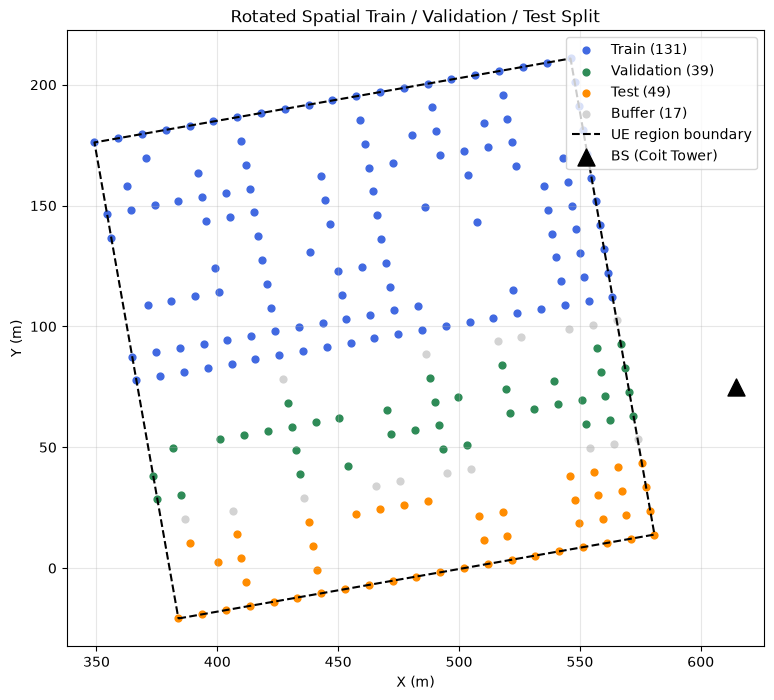

In [ ]:

# Step 3.9 — Visualize rotated spatial dataset split

import matplotlib.pyplot as plt

colors = {
    "train": "royalblue",
    "validation": "seagreen",
    "test": "darkorange",
    "buffer": "lightgray"
}

plt.figure(figsize=(9, 8))

for split, color in colors.items():

    positions = np.array([
        position
        for location_id, position in enumerate(outdoor_positions)
        if location_splits[location_id] == split
    ]).reshape(-1, 3)

    if len(positions) > 0:
        plt.scatter(
            positions[:, 0],
            positions[:, 1],
            color=color,
            s=24,
            label=f"{split.capitalize()} ({len(positions)})"
        )

# Draw rotated square boundary
corners_local = np.array([
    [-100, -100],
    [100, -100],
    [100, 100],
    [-100, 100],
    [-100, -100]
])

c = np.cos(rotation_rad)
s = np.sin(rotation_rad)

corners_global = np.column_stack((
    center_x + corners_local[:, 0]*c - corners_local[:, 1]*s,
    center_y + corners_local[:, 0]*s + corners_local[:, 1]*c
))

plt.plot(
    corners_global[:, 0],
    corners_global[:, 1],
    color="black",
    linewidth=1.5,
    linestyle="--",
    label="UE region boundary"
)

bs_xyz = bs.position.numpy().reshape(-1)

plt.scatter(
    bs_xyz[0], bs_xyz[1],
    color="black",
    marker="^",
    s=150,
    label="BS (Coit Tower)"
)

plt.xlabel("X (m)")
plt.ylabel("Y (m)")
plt.title("Rotated Spatial Train / Validation / Test Split")

plt.axis("equal")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


In [ ]:

# Step 2 — Verify BS orientation and downtilt

import numpy as np

bs = scene.get("bs")

# Use the actual current BS position
bs_xyz = bs.position.numpy().reshape(-1)

# Aim at the selected outdoor target
bs.look_at(aim_point.tolist())

target_xyz = np.asarray(aim_point)

delta = target_xyz - bs_xyz

horizontal_distance = np.linalg.norm(delta[:2])

downtilt_deg = np.degrees(
    np.arctan2(-delta[2], horizontal_distance)
)

print("BS position:", bs_xyz)
print("Target:", target_xyz)
print("Horizontal distance:", horizontal_distance, "m")
print("Downtilt:", downtilt_deg, "degrees")
print("Sionna orientation:", bs.orientation)


BS position: [614.7   74.79 150.8 ]
Target: [465.          95.          52.64714432]
Horizontal distance: 151.058060750758 m
Downtilt: 33.01456594557098 degrees
Sionna orientation: [[3.0074, 0.576213, 0]]


In [ ]:
# Export FINAL rotated UE region to Blender

import pandas as pd
from google.colab import files

# Verify that the data is consistent
assert len(outdoor_positions) == len(location_splits)
assert len(ue_dataset) == 3 * len(outdoor_positions)

rows = []

for location_id, position in enumerate(outdoor_positions):
    rows.append({
        "x": float(position[0]),
        "y": float(position[1]),
        "z": float(position[2]),
        "split": location_splits[location_id]
    })

df = pd.DataFrame(rows)

csv_filename = "ue_splits_465_95_rot10_FINAL.csv"
df.to_csv(csv_filename, index=False)

print("Exported locations:", len(df))
print(df["split"].value_counts())

assert len(df) == 236, "Check previous dataset cells"

files.download(csv_filename)




Exported locations: 236
split
train         131
test           49
validation     39
buffer         17
Name: count, dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

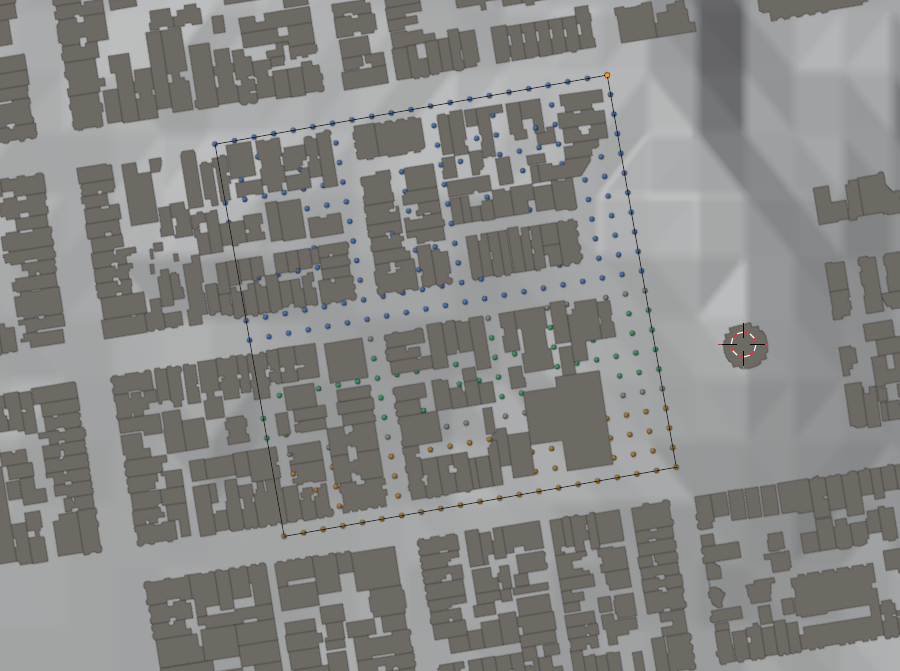

In [ ]:
# ---- numerology and helpers (numpy only) ----
import os, math, time, inspect, itertools
import numpy as np
import matplotlib.pyplot as plt

FC     = 3.5e9
C0     = 299_792_458.0
SCS    = 30e3
N_PRB  = 24
NSC    = 12 * N_PRB                 # 288 subcarriers
NSYM   = 14
T_SYM  = 0.5e-3 / NSYM              # mean OFDM symbol duration incl. CP (30 kHz SCS -> 0.5 ms slot)
T_SLOT = NSYM * T_SYM
SPEEDS = [3, 30, 120]               # km/h
FREQS  = (np.arange(NSC) - NSC / 2) * SCS            # baseband subcarrier frequencies
FD_NOM = {v: v / 3.6 * FC / C0 for v in SPEEDS}      # nominal max Doppler [Hz]
SNR_GRID = list(range(-5, 26, 5))                    # dB, used everywhere

print("max Doppler [Hz]:", {v: round(f, 1) for v, f in FD_NOM.items()})
print("Tc = 0.423/fD in OFDM symbols:", {v: round(0.423 / f / T_SYM, 1) for v, f in FD_NOM.items()})


def path_stats(p, tau, fd, dyn_db=30.0):
    """Per-UE multipath statistics.
    p, tau, fd : [n, P] path power, delay (first arrival = 0) and Doppler [Hz]; invalid paths have p == 0.
    Paths more than `dyn_db` below the strongest one are ignored."""
    pmax = p.max(1, keepdims=True)
    keep = (p > 0) & (p >= pmax * 10 ** (-dyn_db / 10))
    w = np.where(keep, p, 0.0)
    tot = np.maximum(w.sum(1), 1e-30)
    mom = lambda x, k: (w * np.where(keep, x, 0.0) ** k).sum(1) / tot
    t1, t2, t4 = mom(tau, 1), mom(tau, 2), mom(tau, 4)
    return dict(
        tau_rms=np.sqrt(np.maximum(t2 - t1 ** 2, 0)),          # RMS delay spread
        tau_max=np.where(keep, tau, 0).max(1),                 # max excess delay (within dyn_db)
        tau4=t4 ** 0.25,                                       # 4th-moment delay (interp. error predictor)
        fd2=mom(fd, 2) ** 0.5,                                 # RMS Doppler
        fd4=mom(fd, 4) ** 0.25,
        fd_max=np.where(keep, np.abs(fd), 0).max(1))


def subarray(H, M):
    """H: [n, 16, T, F] from the 4x4 trace -> M x M sub-array, re-normalised to unit mean power per UE.
    Element index = row*4+col, so the top-left 2x2 block is {0,1,4,5} for either ordering convention."""
    idx = {1: [0], 2: [0, 1, 4, 5], 4: list(range(16))}[M]
    Hs = H[:, idx]
    pw = (np.abs(Hs) ** 2).mean(axis=(1, 2, 3), keepdims=True)
    return (Hs / np.sqrt(np.maximum(pw, 1e-30))).astype(np.complex64)

max Doppler [Hz]: {3: 9.7, 30: 97.3, 120: 389.2}
Tc = 0.423/fD in OFDM symbols: {3: 1217.4, 30: 121.7, 120: 30.4}


In [ ]:
# [needs-sionna, needs-torch]
import torch
from sionna.rt import Transmitter, PathSolver
from sionna.phy.channel import cir_to_ofdm_channel

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# Propagation mechanisms (document these in the report): LoS + specular reflection + diffraction, depth 4.
# Refraction (through-building) and diffuse scattering are off: UEs are outdoor and the scene materials have
# no scattering coefficients set.
SOLVER_OPTS = dict(max_depth=4, los=True, specular_reflection=True, diffuse_reflection=False,
                   refraction=False, diffraction=True, samples_per_src=500_000)
p_solver = PathSolver()

def trace(scene):
    """Call PathSolver, silently dropping kwargs your Sionna version does not know (CHECK printed list)."""
    sig = inspect.signature(PathSolver.__call__).parameters
    kw = {k: v for k, v in SOLVER_OPTS.items() if k in sig}
    dropped = [k for k in SOLVER_OPTS if k not in sig]
    if dropped: print("PathSolver does not accept:", dropped)
    return p_solver(scene, **kw)

_freqs_t = torch.as_tensor(FREQS, dtype=torch.float32, device=device)

def generate_channels(scene, pos, dirs, speed_kmh, bs_pos, chunk=24):
    """Uplink: UEs are transmitters (with velocity), the BS is the receiver -> no reverse_direction needed.
    Returns H [n, A, NSYM, NSC] (unit mean power per UE) and per-UE statistics."""
    Hs, st, los, gain, ok = [], {k: [] for k in ("tau_rms","tau_max","tau4","fd2","fd4","fd_max")}, [], [], []
    for s in range(0, len(pos), chunk):
        ids = list(range(s, min(s + chunk, len(pos))))
        for i in ids:
            scene.add(Transmitter(name=f"ue_{i}", position=[float(x) for x in pos[i]]))
            v = speed_kmh / 3.6 * np.array([np.cos(dirs[i]), np.sin(dirs[i]), 0.0])
            scene.get(f"ue_{i}").velocity = [float(x) for x in v]          # CHECK: velocity setter
        paths = trace(scene)
        a, tau = paths.cir(sampling_frequency=1 / T_SYM, num_time_steps=NSYM,
                           normalize_delays=False, out_type="torch")        # CHECK signature in 2.x
        a, tau = torch.as_tensor(a).to(device), torch.as_tensor(tau).to(device)
        assert tau.ndim == 3, "expected synthetic-array paths: tau [rx, tx, paths]"
        # a: [1, A, n_tx, 1, P, T]   tau: [1, n_tx, P]
        pw   = (a.abs() ** 2).mean(dim=(1, 5))[0, :, 0, :]                  # [n_tx, P]
        tau0 = tau[0]
        valid = (tau0 >= 0) & (pw > 0)
        tmin = torch.where(valid, tau0, torch.full_like(tau0, 1e9)).min(-1).values
        taun = torch.where(valid, tau0 - tmin[:, None], torch.zeros_like(tau0))
        ph = (a[..., 1:] * a[..., :-1].conj()).sum(dim=(1, 5))[0, :, 0, :]  # Doppler from phase slope
        fd = torch.angle(ph) / (2 * np.pi * T_SYM)
        a_b = a.permute(2, 0, 1, 3, 4, 5).unsqueeze(3)                      # [n_tx,1,A,1,1,P,T]
        h = cir_to_ofdm_channel(_freqs_t, a_b, taun[:, None, None, :], normalize=False)
        h = h[:, 0, :, 0, 0]                                                # [n_tx, A, T, NSC]
        pwr = (h.abs() ** 2).mean(dim=(1, 2, 3))
        h = h / torch.sqrt(pwr.clamp_min(1e-30)).view(-1, 1, 1, 1)
        stt = path_stats(pw.cpu().numpy(), taun.cpu().numpy(), fd.cpu().numpy())
        for k in st: st[k].append(stt[k])
        dist = np.linalg.norm(np.asarray(pos[ids]) - np.asarray(bs_pos)[None], axis=1)
        los.append(tmin.cpu().numpy() * C0 - dist < 0.1)                    # earliest path == geometric distance
        gain.append(10 * np.log10(pwr.cpu().numpy() + 1e-30))
        ok.append(valid.any(-1).cpu().numpy())
        Hs.append(h.cpu().numpy().astype(np.complex64))
        for i in ids: scene.remove(f"ue_{i}")
    out = {k: np.concatenate(v) for k, v in st.items()}
    out.update(H=np.concatenate(Hs), los=np.concatenate(los), gain_db=np.concatenate(gain), ok=np.concatenate(ok))
    return out


def generate_dataset(scene, positions, splits, loc_dirs, bs_pos, speeds=SPEEDS, k_aug=1, seed=1, chunk=24):
    """k = 0 : all non-buffer locations, the direction you already drew in Step 3.6 (same direction for every speed).
    k >= 1: extra random directions for TRAIN locations only (data augmentation for the learned estimators)."""
    rng = np.random.default_rng(seed)
    dirs = [loc_dirs] + [rng.uniform(0, 2 * np.pi, len(positions)) for _ in range(k_aug - 1)]
    cols = {}
    t0 = time.time()
    for k in range(k_aug):
        sel = np.where(splits != "buffer")[0] if k == 0 else np.where(splits == "train")[0]
        for v in speeds:
            r = generate_channels(scene, positions[sel], dirs[k][sel], v, bs_pos, chunk)
            keep = r["ok"]                                       # drop UEs with no propagation path
            n = int(keep.sum())
            meta = dict(speed=np.full(n, v), loc=sel[keep], split=splits[sel][keep], dir_id=np.full(n, k),
                        pos=positions[sel][keep])
            for key, val in {**{kk: r[kk][keep] for kk in r if kk != "ok"}, **meta}.items():
                cols.setdefault(key, []).append(val)
            print(f"k={k} speed={v:>3} km/h: {n}/{len(sel)} UEs with paths   [{time.time()-t0:.0f}s]")
    return {k: np.concatenate(v) for k, v in cols.items()}

device: cuda


In [ ]:
# [needs-sionna, needs-torch]  Run ray tracing ONCE with the 4x4 array (M = 1, 2 are sub-arrays of it).
K_AUG = 1          # set to 3-4 if the learned models overfit: extra random UE directions for TRAIN locations only
M_TRACE = 4

scene.rx_array = PlanarArray(num_rows=M_TRACE, num_cols=M_TRACE, vertical_spacing=0.5,
                             horizontal_spacing=0.5, pattern="tr38901", polarization="V")
bs = scene.get("bs")
bs_pos = bs.position.numpy().reshape(-1)

n_loc = len(outdoor_positions)
splits_arr = np.array([location_splits[i] for i in range(n_loc)])
loc_dirs   = np.array([ue_dataset[3 * i]["direction_rad"] for i in range(n_loc)])    # from Step 3.6

ds = generate_dataset(scene, outdoor_positions, splits_arr, loc_dirs, bs_pos, k_aug=K_AUG)
print({k: v.shape for k, v in ds.items()})
torch.save(ds, "channel_dataset_4x4.pt")       # .pt file with channels + metadata (position, LoS flag, tau_rms, speed ...)

k=0 speed=  3 km/h: 110/219 UEs with paths   [10s]
k=0 speed= 30 km/h: 110/219 UEs with paths   [15s]
k=0 speed=120 km/h: 110/219 UEs with paths   [20s]
{'tau_rms': (330,), 'tau_max': (330,), 'tau4': (330,), 'fd2': (330,), 'fd4': (330,), 'fd_max': (330,), 'H': (330, 16, 14, 288), 'los': (330,), 'gain_db': (330,), 'speed': (330,), 'loc': (330,), 'split': (330,), 'dir_id': (330,), 'pos': (330, 3)}


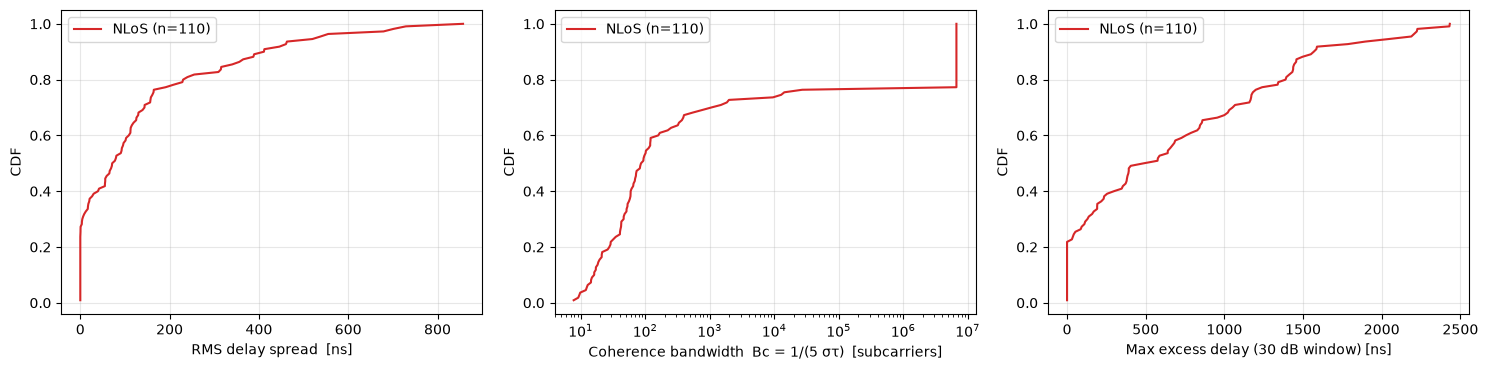

LoS fraction: 0.00
NLoS : median στ=  74.4 ns | median Bc=  89.7 sc | 90th pct τmax= 1569.6 ns

Time selectivity (nominal):
    3 km/h: fD=   9.7 Hz | Tc=0.423/fD=  43.48 ms =  1217.4 OFDM symbols | phase drift over a slot =  0.03 rad
   30 km/h: fD=  97.3 Hz | Tc=0.423/fD=   4.35 ms =   121.7 OFDM symbols | phase drift over a slot =  0.31 rad
  120 km/h: fD= 389.2 Hz | Tc=0.423/fD=   1.09 ms =    30.4 OFDM symbols | phase drift over a slot =  1.22 rad
  measured max |Doppler| over UEs @ 3 km/h: 9.7 Hz (95th pct)
  measured max |Doppler| over UEs @ 30 km/h: 97.1 Hz (95th pct)
  measured max |Doppler| over UEs @ 120 km/h: 388.5 Hz (95th pct)


In [ ]:
# ---- Channel statistics (numpy only) ----
def coherence(ds):
    sel = (ds["speed"] == SPEEDS[0]) & (ds["dir_id"] == 0)      # delay statistics do not depend on speed
    tau_rms, tau_max, los = ds["tau_rms"][sel], ds["tau_max"][sel], ds["los"][sel]
    Bc = 1 / (5 * np.maximum(tau_rms, 1e-12))            # Hz
    return tau_rms, tau_max, Bc / SCS, los

def cdf(ax, x, label, **kw):
    x = np.sort(x); ax.plot(x, np.arange(1, len(x) + 1) / len(x), label=f"{label} (n={len(x)})", **kw)

def plot_stats(ds):
    tau_rms, tau_max, Bc_sc, los = coherence(ds)
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for m, lab, c in ((los, "LoS", "tab:blue"), (~los, "NLoS", "tab:red")):
        if m.sum() == 0: continue
        cdf(ax[0], tau_rms[m] * 1e9, lab, color=c); cdf(ax[1], Bc_sc[m], lab, color=c); cdf(ax[2], tau_max[m] * 1e9, lab, color=c)
    ax[0].set_xlabel("RMS delay spread  [ns]"); ax[1].set_xlabel("Coherence bandwidth  Bc = 1/(5 στ)  [subcarriers]")
    ax[2].set_xlabel("Max excess delay (30 dB window) [ns]"); ax[1].set_xscale("log")
    for a_ in ax: a_.set_ylabel("CDF"); a_.grid(alpha=.3); a_.legend()
    plt.tight_layout(); plt.show()
    print(f"LoS fraction: {los.mean():.2f}")
    for m, lab in ((los, "LoS"), (~los, "NLoS")):
        if m.sum():
            print(f"{lab:5s}: median στ={np.median(tau_rms[m])*1e9:6.1f} ns | median Bc={np.median(Bc_sc[m]):6.1f} sc "
                  f"| 90th pct τmax={np.percentile(tau_max[m],90)*1e9:7.1f} ns")
    print("\nTime selectivity (nominal):")
    for v in SPEEDS:
        fd = FD_NOM[v]; print(f"  {v:>3} km/h: fD={fd:6.1f} Hz | Tc=0.423/fD={0.423/fd*1e3:7.2f} ms = {0.423/fd/T_SYM:7.1f} OFDM symbols"
                              f" | phase drift over a slot = {2*np.pi*fd*T_SLOT:5.2f} rad")
    for v in SPEEDS:
        s = ds["speed"] == v
        print(f"  measured max |Doppler| over UEs @ {v} km/h: {np.percentile(ds['fd_max'][s], 95):.1f} Hz (95th pct)")

plot_stats(ds)

In [ ]:
import pandas as pd

WIN = 96                                   # sub-band (8 PRBs) used by the windowed estimators / learned filters

def dmrs_symbols(add_pos, l0=2):          # PUSCH mapping type A, 14 symbols (TS 38.211, Table 6.4.1.1.3-3)
    return {0: [l0], 1: [l0, 11], 2: [l0, 7, 11], 3: [l0, 5, 8, 11]}[add_pos]

def make_cfg(name, sym_idx, pil_sc, res_sc, kind):
    Tp, Fp = np.array(sorted(sym_idx)), np.where(pil_sc)[0]
    pilot = np.zeros((NSYM, NSC), bool); pilot[np.ix_(Tp, Fp)] = True
    reserved = np.zeros((NSYM, NSC), bool); reserved[np.ix_(Tp, np.where(res_sc)[0])] = True
    gap_t = np.diff(Tp).max() if len(Tp) > 1 else 0
    edge = max(Tp[0], NSYM - 1 - Tp[-1])
    return dict(name=name, kind=kind, Tp=Tp, Fp=Fp, Fp_w=Fp[Fp < WIN], pilot=pilot, reserved=reserved,
                n_pilot=int(pilot.sum()), n_reserved=int(reserved.sum()), n_data=int((~reserved).sum()),
                eta=reserved.sum() / (NSYM * NSC), df_max=int(np.diff(Fp).max()), df_mean=NSC / len(Fp),
                dt_eff=int(max(gap_t, 2 * edge)), n_psym=len(Tp))

def nr_cfg(ctype, add_pos, ncdm):
    k = np.arange(NSC)
    if ctype == 1:
        pil = k % 2 == 0;  res = pil if ncdm == 1 else np.ones(NSC, bool)
    else:
        pil = (k % 6) < 2; res = {1: (k % 6) < 2, 2: (k % 6) < 4, 3: np.ones(NSC, bool)}[ncdm]
    return make_cfg(f"NR-T{ctype}-p{add_pos}" + (f"-cdm{ncdm}" if ncdm > 1 else ""), dmrs_symbols(add_pos), pil, res, "NR")

def comb_cfg(spacing, syms):
    pil = (np.arange(NSC) % spacing) == 0
    return make_cfg(f"comb{spacing}-{len(syms)}sym", syms, pil, pil, "custom")

CONFIGS = [nr_cfg(1, 3, 1), nr_cfg(1, 2, 1), nr_cfg(1, 1, 2), nr_cfg(1, 1, 1), nr_cfg(1, 0, 1),
           nr_cfg(2, 1, 2), nr_cfg(2, 1, 1), nr_cfg(2, 0, 1),
           comb_cfg(4, [2]), comb_cfg(8, [2]), comb_cfg(16, [2, 11]), comb_cfg(32, [2, 11])]
CFG = {c["name"]: c for c in CONFIGS}
for c in CONFIGS:                                    # the estimators below assume pilots = Tp x Fp (separable)
    assert c["pilot"].sum() == len(c["Tp"]) * len(c["Fp"])
    assert (np.diff(c["Fp"][c["Fp"] < 96]) == np.diff(c["Fp"][(c["Fp"] >= 96) & (c["Fp"] < 192)])).all()

tab = pd.DataFrame([dict(config=c["name"], pilot_syms=c["n_psym"], pilot_REs=c["n_pilot"], reserved_REs=c["n_reserved"],
                         **{"Δf_max[sc]": c["df_max"], "Δf_mean[sc]": round(c["df_mean"], 1), "Δt_eff[sym]": c["dt_eff"]},
                         **{"η [%]": round(100 * c["eta"], 2)}) for c in CONFIGS]).sort_values("η [%]", ascending=False)
print(tab.to_string(index=False))

       config  pilot_syms  pilot_REs  reserved_REs  Δf_max[sc]  Δf_mean[sc]  Δt_eff[sym]  η [%]
     NR-T1-p3           4        576           576           2          2.0            4  14.29
NR-T1-p1-cdm2           2        288           576           2          2.0            9  14.29
     NR-T1-p2           3        432           432           2          2.0            5  10.71
NR-T2-p1-cdm2           2        192           384           5          3.0            9   9.52
     NR-T1-p1           2        288           288           2          2.0            9   7.14
     NR-T2-p1           2        192           192           5          3.0            9   4.76
     NR-T1-p0           1        144           144           2          2.0           22   3.57
     NR-T2-p0           1         96            96           5          3.0           22   2.38
   comb4-1sym           1         72            72           4          4.0           22   1.79
   comb8-1sym           1         36    

In [ ]:
# [needs-sionna] OPTIONAL cross-check: your NR masks vs. Sionna's PUSCH pilot pattern (CHECK attribute names in 2.x)
try:
    from sionna.phy.nr import PUSCHConfig, PUSCHTransmitter
    for (ct, ap, nc) in [(1, 1, 1), (1, 1, 2), (2, 1, 1)]:
        pc = PUSCHConfig()
        pc.carrier.subcarrier_spacing = 30; pc.carrier.n_size_grid = N_PRB
        pc.dmrs.config_type = ct; pc.dmrs.additional_position = ap; pc.dmrs.num_cdm_groups_without_data = nc
        mask = np.asarray(PUSCHTransmitter(pc).resource_grid.pilot_pattern.mask)[0, 0].astype(bool)
        mine = nr_cfg(ct, ap, nc)["reserved"]
        print((ct, ap, nc), "mask identical to Sionna:", bool((mask == mine).all()))
except Exception as e:
    print("Cross-check skipped:", repr(e))

Cross-check skipped: TypeError("can't convert cuda:0 device type tensor to numpy. Use Tensor.cpu() to copy the tensor to host memory first.")


In [ ]:
FAIL_DB = -15.0
def predict(cfg, d):
    v = int(d["speed"][0]); fD = FD_NOM[v]
    nyq_f = cfg["df_max"] * SCS * d["tau_max"] <= 1
    nyq_t = np.full(nyq_f.shape, cfg["dt_eff"] * T_SYM * 2 * fD <= 1)      # depends on speed only
    nf = (2 * np.pi * cfg["df_max"] * SCS * d["tau4"]) ** 4 / 120
    if cfg["n_psym"] > 1:
        nt = (2 * np.pi * d["fd4"] * cfg["dt_eff"] * T_SYM) ** 4 / 120
    else:
        dist = np.arange(NSYM) - cfg["Tp"][0]
        nt = (2 * np.pi * d["fd2"] * T_SYM) ** 2 * np.mean(dist ** 2)
    nmse = np.minimum(nf + nt, 2.0)
    return nyq_f, nyq_t, nmse

def prediction_table(ds, split="test"):
    rows = []
    for c in CONFIGS:
        row = {"config": c["name"], "η[%]": round(100 * c["eta"], 2)}
        for v in SPEEDS:
            sel = (ds["split"] == split) & (ds["speed"] == v) & (ds["dir_id"] == 0)
            d = {k: ds[k][sel] for k in ("speed", "tau_max", "tau4", "fd2", "fd4")}
            nf, nt, nm = predict(c, d)
            med = 10 * np.log10(np.median(nm))
            row[f"{v}km/h: Nyq-f fail%"] = round(100 * (1 - nf.mean()))
            row[f"{v}km/h: Nyq-t fail%"] = round(100 * (1 - nt.mean()))
            row[f"{v}km/h: pred. NMSE_lin[dB]"] = round(med, 1)
            row[f"{v}km/h: verdict"] = "FAIL" if med > FAIL_DB else "ok"
        rows.append(row)
    return pd.DataFrame(rows)

PRED = prediction_table(ds)
print(PRED.to_string(index=False))

       config  η[%]  3km/h: Nyq-f fail%  3km/h: Nyq-t fail%  3km/h: pred. NMSE_lin[dB] 3km/h: verdict  30km/h: Nyq-f fail%  30km/h: Nyq-t fail%  30km/h: pred. NMSE_lin[dB] 30km/h: verdict  120km/h: Nyq-f fail%  120km/h: Nyq-t fail%  120km/h: pred. NMSE_lin[dB] 120km/h: verdict
     NR-T1-p3 14.29                   0                   0                 -44.200001             ok                    0                    0                  -44.200001              ok                     0                     0                   -42.299999               ok
     NR-T1-p2 10.71                   0                   0                 -44.200001             ok                    0                    0                  -44.200001              ok                     0                     0                   -38.700001               ok
NR-T1-p1-cdm2 14.29                   0                   0                 -44.200001             ok                    0                    0                  -44.0

In [ ]:
# ---- data views ----
M_EVAL = 4                                   # 1, 2 or 4 (sub-arrays of the 4x4 trace)

def view(ds, M, split, speed=None, base_only=False):
    sel = ds["split"] == split
    if speed is not None: sel &= ds["speed"] == speed
    if base_only: sel &= ds["dir_id"] == 0
    return subarray(ds["H"][sel], M), ds["speed"][sel]

def pilots_of(H, cfg):
    return H[:, :, cfg["Tp"]][:, :, :, cfg["Fp"]]

def noise_like(shape, sig2, rng):
    return ((rng.standard_normal(shape) + 1j * rng.standard_normal(shape)) * np.sqrt(sig2 / 2)).astype(np.complex64)

# ---- LS + interpolation ----
_I = {}
def interp_mats(cfg, kind):
    key = (cfg["name"], kind)
    if key not in _I:
        def mat(nodes, n):
            A = np.zeros((n, len(nodes))); x = np.arange(n)
            for j in range(len(nodes)):
                if kind == "nn":
                    A[:, j] = 0
                else:
                    e = np.zeros(len(nodes)); e[j] = 1; A[:, j] = np.interp(x, nodes, e)   # linear, edge hold
            if kind == "nn":
                A[x, np.argmin(np.abs(x[:, None] - nodes[None]), axis=1)] = 1
            return A.astype(np.float32)
        _I[key] = (mat(cfg["Tp"], NSYM), mat(cfg["Fp"], NSC))
    return _I[key]

def est_ls(Hp, cfg, kind):
    At, Af = interp_mats(cfg, kind)
    return np.einsum("tp,...pf,kf->...tk", At, Hp, Af, optimize=True)

# ---- covariances from data ----
def estimate_cov(H):
    """H [n, A, T, F]  ->  R_f [F,F], R_t [T,T] (unit mean diagonal)."""
    n, A, T, F = H.shape
    Hf = H.reshape(-1, F)
    Rf = (Hf.T @ Hf.conj()) / Hf.shape[0]
    Ht = H.transpose(0, 1, 3, 2).reshape(-1, T)
    Rt = (Ht.T @ Ht.conj()) / Ht.shape[0]
    Rf = Rf / np.real(np.trace(Rf)) * F; Rt = Rt / np.real(np.trace(Rt)) * T
    return Rf.astype(np.complex128), Rt.astype(np.complex128)

class SepLMMSE:
    """LMMSE with R = R_t (x) R_f. y: [..., Tp, Fp] LS estimates -> [..., NSYM, F]."""
    def __init__(self, Rf, Rt, Tp, Fp):
        lt, Ut = np.linalg.eigh(Rt[np.ix_(Tp, Tp)]); lf, Uf = np.linalg.eigh(Rf[np.ix_(Fp, Fp)])
        self.lt, self.lf = np.maximum(lt, 0), np.maximum(lf, 0)
        self.Ut, self.Uf = Ut.astype(np.complex64), Uf.astype(np.complex64)
        self.Gt, self.Gf = Rt[:, Tp].astype(np.complex64), Rf[:, Fp].astype(np.complex64)
    def __call__(self, y, sig2):
        C = self.Ut.conj().T @ y @ self.Uf.conj()
        C = C / (self.lt[:, None] * self.lf[None, :] + sig2).astype(np.float32)
        return self.Gt @ (self.Ut @ C @ self.Uf.T) @ self.Gf.T

def run_windowed(fn_rows, Hp, cfg):
    """Apply a per-window function [R,Tp,Fpw] -> [R,NSYM,WIN] on the nw = NSC/WIN windows of the band."""
    Tp, Fpw, nw = cfg["Tp"], cfg["Fp_w"], NSC // WIN
    lead = Hp.shape[:-2]
    Hw = np.moveaxis(Hp.reshape(*lead, len(Tp), nw, len(Fpw)), -2, -3).reshape(-1, len(Tp), len(Fpw))
    out = fn_rows(Hw).reshape(*lead, nw, NSYM, WIN)
    return np.moveaxis(out, -3, -2).reshape(*lead, NSYM, NSC)

# ---- generic 3GPP TDL covariance (what a receiver without site knowledge would use) ----
def tdl_covs(model="C", delay_spread=300e-9):
    try:
        from sionna.phy.channel import tdl_freq_cov_mat, tdl_time_cov_mat
        toN = lambda x: np.asarray(x.detach().cpu().numpy() if hasattr(x, "detach") else x)
        Rf = toN(tdl_freq_cov_mat(model, SCS, NSC, delay_spread))
        Rt = {v: toN(tdl_time_cov_mat(model, v / 3.6, FC, T_SYM, NSYM)) for v in SPEEDS}
        src = f"Sionna TDL-{model}, DS={delay_spread*1e9:.0f} ns"
    except Exception as e:                       # analytic fallback: exponential PDP + Jakes
        from scipy.special import j0
        d = np.arange(NSC)[:, None] - np.arange(NSC)[None]
        Rf = 1 / (1 + 1j * 2 * np.pi * d * SCS * delay_spread)
        dt = np.arange(NSYM)[:, None] - np.arange(NSYM)[None]
        Rt = {v: j0(2 * np.pi * FD_NOM[v] * dt * T_SYM).astype(complex) for v in SPEEDS}
        src = f"analytic fallback (exp. PDP DS={delay_spread*1e9:.0f} ns + Jakes) because: {e!r}"
    print("generic covariance:", src)
    return Rf.astype(np.complex128), {v: r.astype(np.complex128) for v, r in Rt.items()}

In [ ]:
# ---- build covariances: site-specific (train region), oracle (test region), generic TDL ----
Htr, vtr = view(ds, M_EVAL, "train")
Hte_v = {v: view(ds, M_EVAL, "test", v, base_only=True)[0] for v in SPEEDS}
Hva_v = {v: view(ds, M_EVAL, "validation", v, base_only=True)[0] for v in SPEEDS}
print("train samples", Htr.shape, "| test per speed", {v: h.shape[0] for v, h in Hte_v.items()})

Rf_site, _ = estimate_cov(Htr)
Rt_site = {v: estimate_cov(Htr[vtr == v])[1] for v in SPEEDS}
Hte_all = np.concatenate([Hte_v[v] for v in SPEEDS])
Rf_orac, _ = estimate_cov(Hte_all)
Rt_orac = {v: estimate_cov(Hte_v[v])[1] for v in SPEEDS}
Rf_tdl, Rt_tdl = tdl_covs("C", 300e-9)

COVS = {"site": (Rf_site, Rt_site), "oracle": (Rf_orac, Rt_orac), "tdl": (Rf_tdl, Rt_tdl)}
_L = {}
def lmmse(tag, cfg, v, windowed=False, Rt_from=None):
    """Rt_from: use the time covariance of another speed (mismatch experiments)."""
    Rf, Rt = COVS[tag]; Rt = Rt[Rt_from if Rt_from is not None else v]
    key = (tag, cfg["name"], v, windowed, Rt_from)
    if key not in _L:
        _L[key] = (SepLMMSE(Rf[:WIN, :WIN], Rt, cfg["Tp"], cfg["Fp_w"]) if windowed
                   else SepLMMSE(Rf, Rt, cfg["Tp"], cfg["Fp"]))
    f = _L[key]
    if windowed: return lambda Hp, s2: run_windowed(lambda Y: f(Y, s2), Hp, cfg)
    return lambda Hp, s2: f(Hp, s2)

train samples (213, 16, 14, 288) | test per speed {3: 23, 30: 23, 120: 23}
generic covariance: analytic fallback (exp. PDP DS=300 ns + Jakes) because: ImportError("cannot import name 'tdl_freq_cov_mat' from 'sionna.phy.channel' (/usr/local/lib/python3.13/dist-packages/sionna/phy/channel/__init__.py)")


In [ ]:
# ---- sanity checks for the Kronecker LMMSE and the interpolators (cheap, run once) ----
_c = CFG["NR-T1-p1"]; _rng = np.random.default_rng(0)
_y = noise_like((2, 3, len(_c["Tp"]), len(_c["Fp"])), 1.0, _rng)
_f = SepLMMSE(Rf_site[:WIN, :WIN], Rt_site[3], _c["Tp"], _c["Fp_w"])
_Y = noise_like((2, len(_c["Tp"]), len(_c["Fp_w"])), 1.0, _rng); _s2 = 0.1
_Rpp = np.kron(Rt_site[3][np.ix_(_c["Tp"], _c["Tp"])], Rf_site[:WIN, :WIN][np.ix_(_c["Fp_w"], _c["Fp_w"])])
_Rhp = np.kron(Rt_site[3][:, _c["Tp"]], Rf_site[:WIN, :WIN][:, _c["Fp_w"]])
_ref = (_Rhp @ np.linalg.solve(_Rpp + _s2 * np.eye(_Rpp.shape[0]), _Y.reshape(2, -1).T)).T.reshape(2, NSYM, WIN)
print("Kronecker LMMSE vs brute-force  max abs err:", np.abs(_f(_Y, _s2) - _ref).max())
_h = np.exp(2j * np.pi * 0.01 * np.arange(NSC))[None, None, None, :] * np.ones((1, 1, NSYM, 1))
print("LS-lin reproduces a slow tone, NMSE:",
      np.mean(np.abs(est_ls(pilots_of(_h, _c), _c, "lin") - _h) ** 2) / np.mean(np.abs(_h) ** 2))

Kronecker LMMSE vs brute-force  max abs err: 1.7196093289118007e-05
LS-lin reproduces a slow tone, NMSE: 1.5636632273530445e-05


In [ ]:
# ---- NMSE vs SNR for every config / speed / estimator ----
NMSE = {}                                           # (cfg, speed, estimator) -> array over SNR_GRID

def nmse_curve(H, cfg, fn, snrs=SNR_GRID, reps=2, seed=0):
    rng = np.random.default_rng(seed)
    Hp = pilots_of(H, cfg); den = (np.abs(H) ** 2).sum(); out = np.zeros(len(snrs))
    for i, snr in enumerate(snrs):
        s2 = 10 ** (-snr / 10)
        for _ in range(reps):
            out[i] += (np.abs(H - fn(Hp + noise_like(Hp.shape, s2, rng), s2)) ** 2).sum()
    return out / (reps * den)

def classical(cfg, v):
    return {"LS-nn": lambda Hp, s2: est_ls(Hp, cfg, "nn"),
            "LS-lin": lambda Hp, s2: est_ls(Hp, cfg, "lin"),
            "LMMSE (site)": lmmse("site", cfg, v),
            "LMMSE (site, 8-PRB window)": lmmse("site", cfg, v, windowed=True),
            "LMMSE (TDL)": lmmse("tdl", cfg, v),
            "LMMSE (oracle cov.)": lmmse("oracle", cfg, v)}

def run_classical(cfgs=CONFIGS, data=Hte_v, store=NMSE, tag=""):
    t0 = time.time()
    for c in cfgs:
        for v in SPEEDS:
            for name, fn in classical(c, v).items():
                store[(c["name"], v, name + tag)] = nmse_curve(data[v], c, fn)
        print(f"{c['name']:16s} done  [{time.time()-t0:.0f}s]")

run_classical()

NR-T1-p3         done  [17s]
NR-T1-p2         done  [33s]
NR-T1-p1-cdm2    done  [48s]
NR-T1-p1         done  [66s]
NR-T1-p0         done  [77s]
NR-T2-p1-cdm2    done  [87s]
NR-T2-p1         done  [96s]
NR-T2-p0         done  [105s]
comb4-1sym       done  [112s]
comb8-1sym       done  [117s]
comb16-2sym      done  [121s]
comb32-2sym      done  [123s]


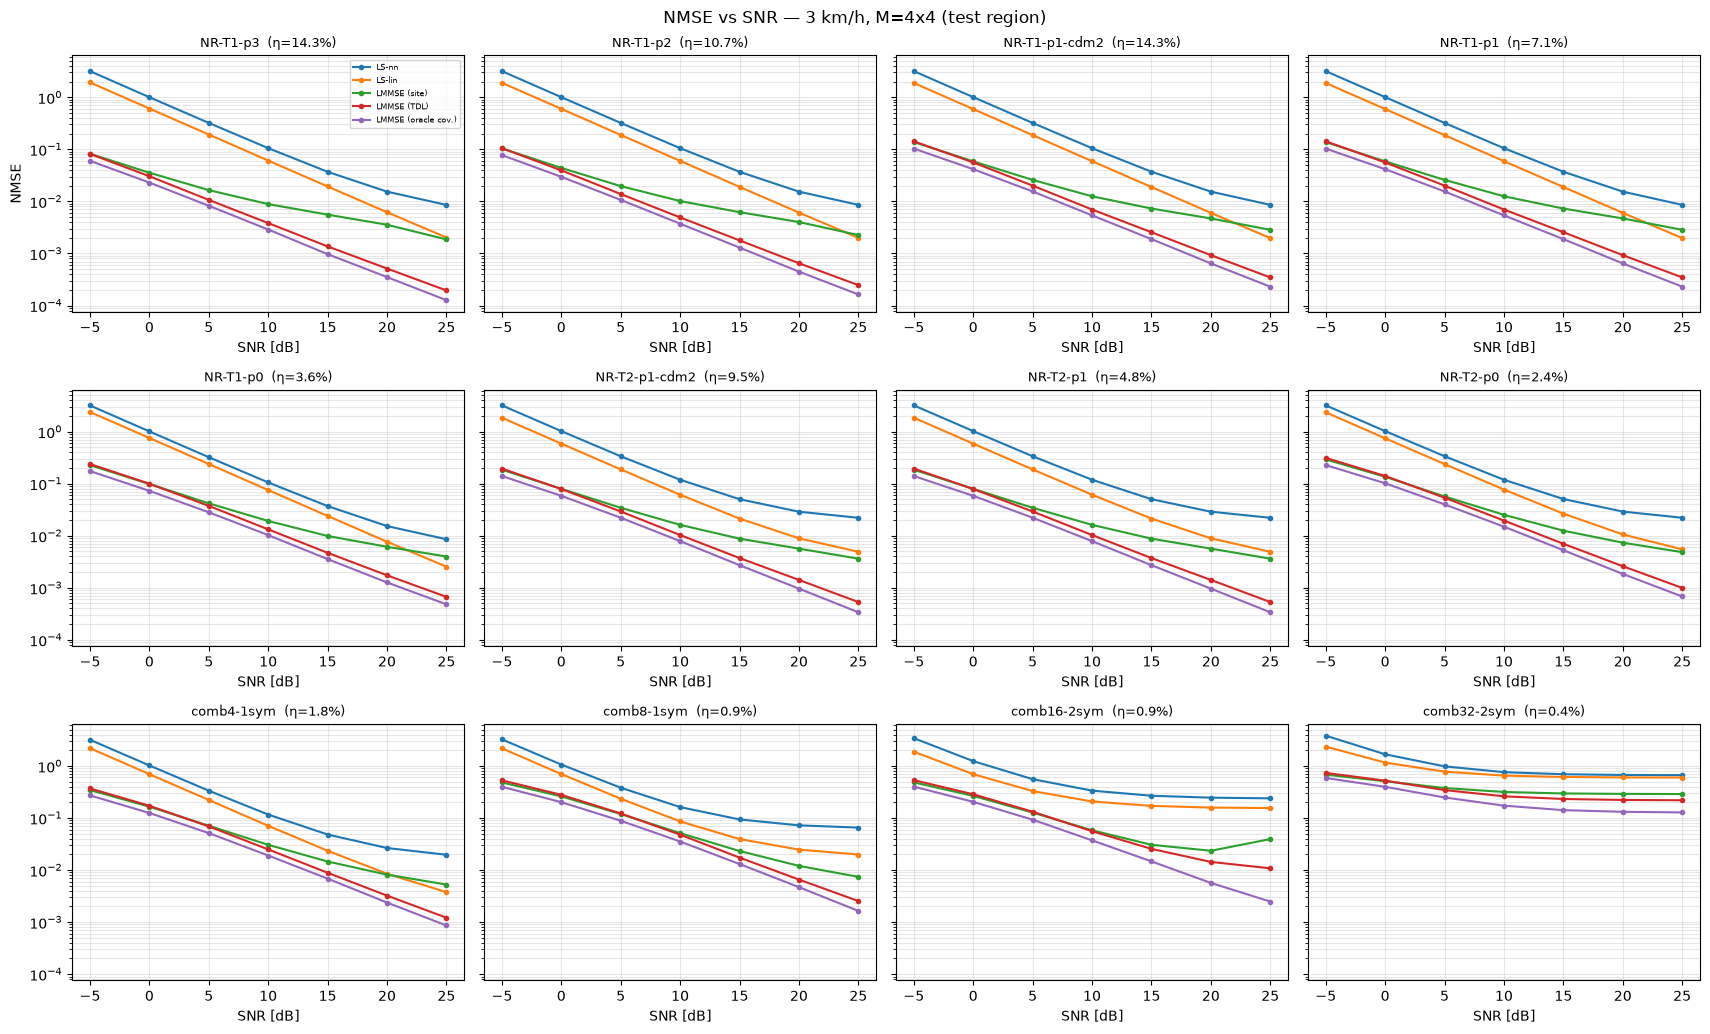

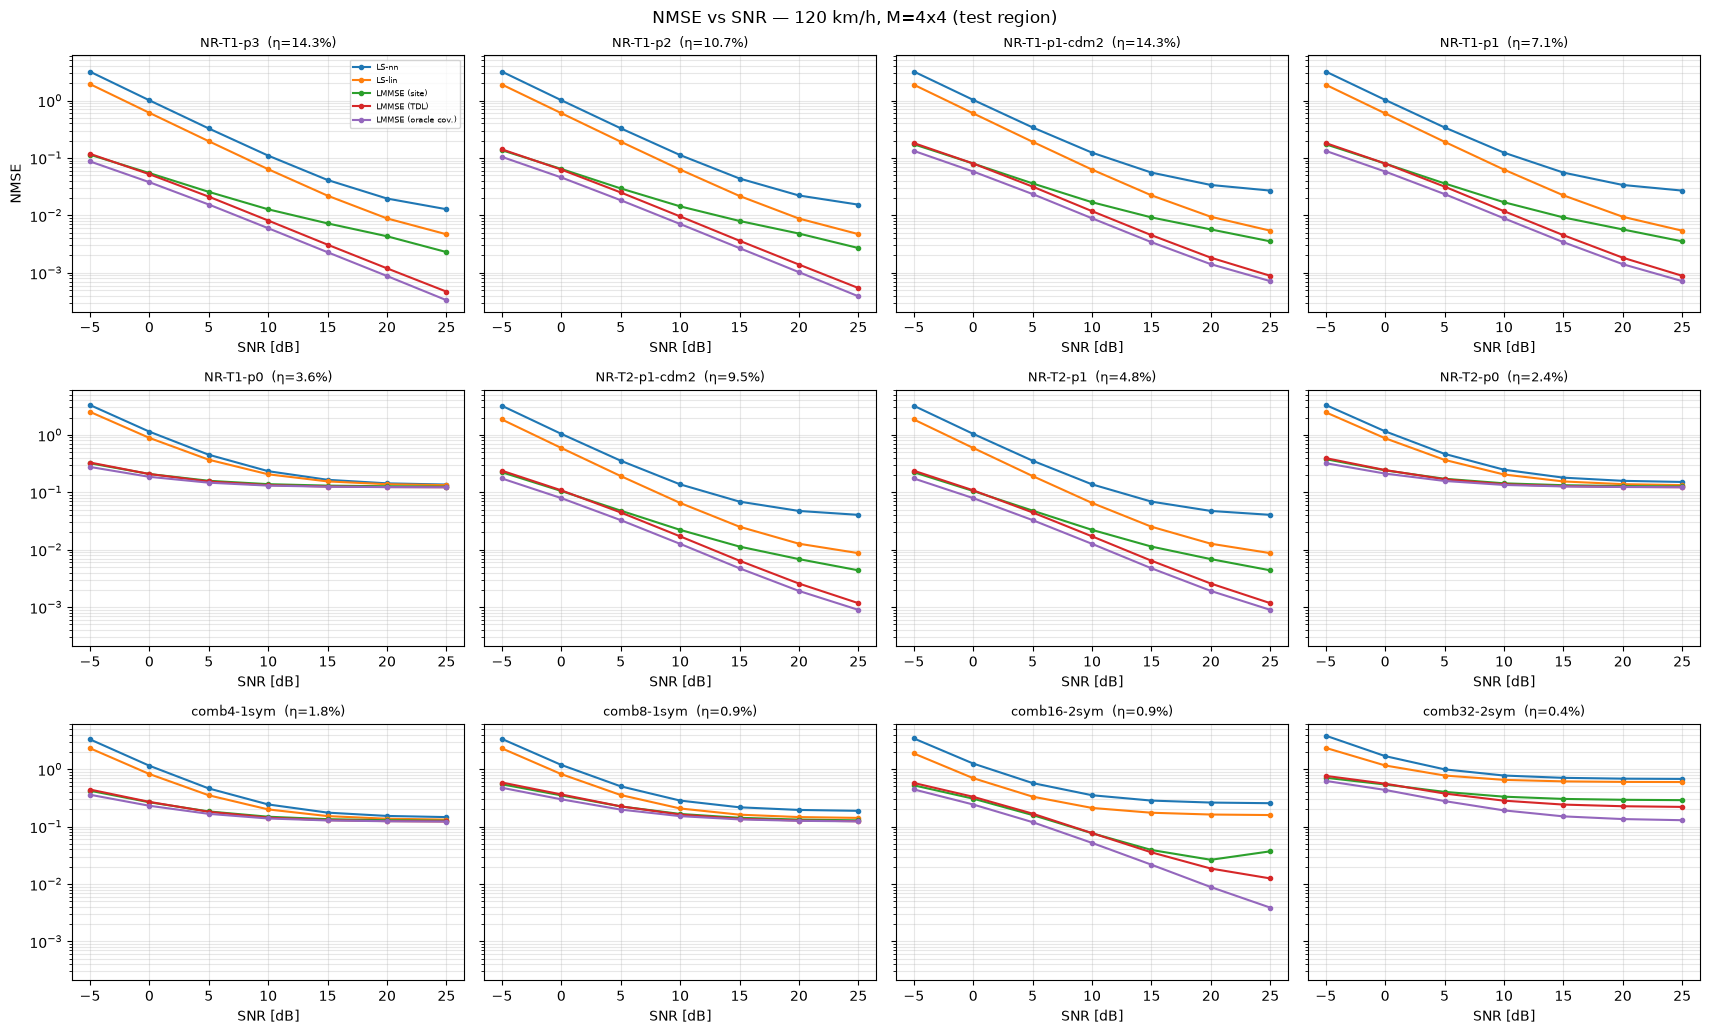


LS-lin NMSE @25 dB [dB]: Step-5 prediction vs measurement
       config  3: predicted  3: measured  30: predicted  30: measured  120: predicted  120: measured
     NR-T1-p3    -27.100000        -26.9     -27.100000         -26.6      -27.000000          -23.3
     NR-T1-p2    -27.100000        -27.0     -27.100000         -26.7      -26.900000          -23.3
NR-T1-p1-cdm2    -27.200001        -27.0     -27.200001         -26.7      -25.299999          -22.7
     NR-T1-p1    -27.200001        -27.0     -27.200001         -26.7      -25.299999          -22.7
     NR-T1-p0    -26.000000        -25.9     -19.200001         -19.6       -8.100000           -8.8
NR-T2-p1-cdm2    -24.799999        -23.1     -24.799999         -22.9      -24.400000          -20.6
     NR-T2-p1    -24.799999        -23.1     -24.799999         -22.9      -24.400000          -20.6
     NR-T2-p0    -24.100000        -22.6     -18.799999         -18.7       -8.000000           -8.8
   comb4-1sym    -25.500000     

In [ ]:
def plot_nmse(v, est_names, cfgs=CONFIGS, ncols=4, store=NMSE, styles=None):
    fig, axs = plt.subplots(int(np.ceil(len(cfgs) / ncols)), ncols, figsize=(4.3 * ncols, 3.5 * np.ceil(len(cfgs) / ncols)), sharey=True)
    for ax, c in zip(np.ravel(axs), cfgs):
        for n in est_names:
            if (c["name"], v, n) in store:
                ax.semilogy(SNR_GRID, store[(c["name"], v, n)], marker="o", ms=3, label=n, **((styles or {}).get(n, {})))
        ax.set_title(f"{c['name']}  (η={100*c['eta']:.1f}%)", fontsize=9); ax.grid(alpha=.3, which="both")
        ax.set_xlabel("SNR [dB]")
    np.ravel(axs)[0].set_ylabel("NMSE"); np.ravel(axs)[0].legend(fontsize=6)
    fig.suptitle(f"NMSE vs SNR — {v} km/h, M={M_EVAL}x{M_EVAL} (test region)"); plt.tight_layout(); plt.show()

for v in (3, 120):
    plot_nmse(v, ["LS-nn", "LS-lin", "LMMSE (site)", "LMMSE (TDL)", "LMMSE (oracle cov.)"])

# Compare measured 25 dB LS-lin NMSE with the Step 5 prediction (interpolation error + LS noise term)
rows = []
for c in CONFIGS:
    r = {"config": c["name"]}
    for v in SPEEDS:
        pr = PRED[PRED.config == c["name"]][f"{v}km/h: pred. NMSE_lin[dB]"].item()
        At, Af = interp_mats(c, "lin"); g = (At ** 2).sum(1).mean() * (Af ** 2).sum(1).mean()     # LS noise gain of the interpolator
        tot = 10 ** (pr / 10) + g * 10 ** (-SNR_GRID[-1] / 10)                                    # interpolation error + noise
        r[f"{v}: predicted"] = round(10 * np.log10(tot), 1); r[f"{v}: measured"] = round(10 * np.log10(NMSE[(c['name'], v, 'LS-lin')][-1]), 1)
    rows.append(r)
print("\nLS-lin NMSE @25 dB [dB]: Step-5 prediction vs measurement"); print(pd.DataFrame(rows).to_string(index=False))
print("\nSite-specific vs generic covariance, NMSE @15 dB [dB] (positive gap = benefit of site knowledge):")
print(pd.DataFrame([{ "config": c["name"], **{f"{v}km/h": round(10*np.log10(NMSE[(c['name'],v,'LMMSE (TDL)')][4] / NMSE[(c['name'],v,'LMMSE (site)')][4]), 1) for v in SPEEDS}} for c in CONFIGS]).to_string(index=False))

In [ ]:
# ---- windowed data + closed-form learned linear filter (numpy) ----
def to_windows(H):
    n, A, T, F = H.shape
    return H.reshape(n * A, T, F // WIN, WIN).transpose(0, 2, 1, 3).reshape(-1, T, WIN)

def fit_ridge(Hw, cfg, sig2, reps=3, lam=1e-4, seed=0):
    rng = np.random.default_rng(seed)
    Hp = Hw[:, cfg["Tp"]][:, :, cfg["Fp_w"]]; B = len(Hw); L = Hp.shape[1] * Hp.shape[2]
    Hf = Hw.reshape(B, -1)
    Ryy = np.zeros((L, L), np.complex128); Rhy = np.zeros((Hf.shape[1], L), np.complex128)
    for _ in range(reps):
        Y = (Hp + noise_like(Hp.shape, sig2, rng)).reshape(B, L)
        Ryy += Y.T @ Y.conj(); Rhy += Hf.T @ Y.conj()
    Ryy /= reps * B; Rhy /= reps * B
    return (Rhy @ np.linalg.inv(Ryy + lam * np.trace(Ryy).real / L * np.eye(L))).astype(np.complex64)     # [D, L]

def fit_all_ridge(cfg, Htr_=None, vtr_=None, speeds=SPEEDS):
    Htr_ = Htr if Htr_ is None else Htr_; vtr_ = vtr if vtr_ is None else vtr_
    return {(snr, v): fit_ridge(to_windows(Htr_[vtr_ == v]), cfg, 10 ** (-snr / 10)) for v in speeds for snr in SNR_GRID}

def window_filter_est(Wd, cfg, v_cond):
    """Wd: {(snr, speed): W[D, L]}. v_cond: the speed the filter was designed for (differs from the true speed in mismatch tests)."""
    def fn(Hp, s2):
        W = Wd[(int(round(-10 * np.log10(s2))), v_cond)]
        return run_windowed(lambda Y: (Y.reshape(len(Y), -1) @ W.T).reshape(-1, NSYM, WIN), Hp, cfg)
    return fn

def truncate_filters(Wd, frac):
    """RA-A-MMSE: rank-r factorisation W ~ A B^T via truncated SVD (r = frac * L)."""
    out = {}
    for k, W in Wd.items():
        U, S, Vh = np.linalg.svd(W, full_matrices=False); r = max(1, int(round(frac * len(S))))
        out[k] = ((U[:, :r] * S[:r]) @ Vh[:r]).astype(np.complex64)
    return out

In [ ]:
# [needs-torch]  A-MMSE: attention encoder that generates the linear filter
import torch, torch.nn as nn
device = globals().get("device") or torch.device("cuda" if torch.cuda.is_available() else "cpu")

class AMMSE(nn.Module):
    def __init__(self, L, N=WIN, M=NSYM, heads_f=8, ff_f=4, ff_t=2, n_res=2):
        super().__init__()
        self.L, self.N, self.M = L, N, M; D = N * M
        self.const = nn.Parameter(0.02 * torch.randn(2 * L))          # learned context ("past pilots"), Re/Im of L pilots
        self.pos   = nn.Parameter(0.02 * torch.randn(2 * L, N))       # token identity
        self.emb   = nn.Linear(1, N)                                  # Eq.(22): scalar -> N-dim embedding (d_e = N)
        self.cond  = nn.Linear(2, N)                                  # (SNR, speed) conditioning
        self.freq  = nn.TransformerEncoderLayer(N, heads_f, ff_f * N, dropout=0.0, batch_first=True)   # MHA + Add&Norm + FFN
        self.proj  = nn.Linear(N, D)                                  # Eq.(25): projection to d_p = N*M
        self.temp  = nn.TransformerEncoderLayer(D, M, ff_t * D, dropout=0.0, batch_first=True)         # heads = M
        self.res   = nn.ModuleList([nn.Sequential(nn.Linear(D, D), nn.ReLU(), nn.Linear(D, D)) for _ in range(n_res)])
        self.norm  = nn.ModuleList([nn.LayerNorm(D) for _ in range(n_res)])
    def forward(self, snr_db, speed_kmh):
        c = torch.tensor([[snr_db / 30.0, math.log10(speed_kmh) / 2.0]], device=self.const.device, dtype=torch.float32)
        t = self.emb(self.const.view(1, -1, 1)) + self.pos[None] + self.cond(c)[:, None, :]          # [1, 2L, N]
        t = self.proj(self.freq(t))                                                                   # [1, 2L, D]
        t = self.temp(t)
        for blk, ln in zip(self.res, self.norm): t = ln(t + blk(t))                                   # ResFC decoder
        Y = t[0] / self.L                                                                             # [2L, D]
        return torch.complex(Y[:self.L], Y[self.L:]).T                                                # Eq.(28-30): W [D, L]

def _win_t(H): return torch.as_tensor(to_windows(H)).to(device)

def train_ammse(cfg, steps=3000, B=256, lr=2e-4, train_speeds=SPEEDS, seed=0, val_every=500, snr_range=(-5.0, 25.0)):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    Tp = torch.as_tensor(cfg["Tp"], device=device); Fp = torch.as_tensor(cfg["Fp_w"], device=device)
    L, D = len(cfg["Tp"]) * len(cfg["Fp_w"]), NSYM * WIN
    tr = {v: _win_t(Htr[vtr == v]) for v in train_speeds}; va = {v: _win_t(Hva_v[v]) for v in train_speeds}
    model = AMMSE(L).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    def nmse(Hb, snr, v):
        Y = Hb[:, Tp][:, :, Fp]; Y = Y + torch.randn_like(Y) * math.sqrt(10 ** (-snr / 10))
        Hh = Y.reshape(len(Hb), L) @ model(snr, v).T
        return (Hh - Hb.reshape(len(Hb), D)).abs().pow(2).sum() / Hb.abs().pow(2).sum()
    best, best_state = 1e9, None
    for it in range(1, steps + 1):
        v = int(rng.choice(train_speeds)); snr = float(rng.uniform(*snr_range))
        Hb = tr[v][torch.randint(len(tr[v]), (B,), device=device)]
        loss = nmse(Hb, snr, v)
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
        if it % val_every == 0 or it == steps:
            with torch.no_grad():
                sc = float(np.mean([10 * math.log10(nmse(va[v_][:512], s, v_).item()) for v_ in train_speeds for s in SNR_GRID]))
            if sc < best: best, best_state = sc, {k: x.detach().clone() for k, x in model.state_dict().items()}
            print(f"  [{cfg['name']}] step {it:5d}  train NMSE {10*math.log10(loss.item()):6.2f} dB | val (mean over SNR/speed) {sc:6.2f} dB")
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        Wd = {(snr, v): model(float(snr), v).cpu().numpy() for v in train_speeds for snr in SNR_GRID}
    return model, Wd

In [ ]:
# [needs-torch]  CNN estimator (non-linear baseline). One model for all pilot patterns: the mask is an input channel.
class ResBlk(nn.Module):
    def __init__(self, c, d):
        super().__init__()
        self.a = nn.Conv2d(c, c, 3, padding=(1, d), dilation=(1, d)); self.b = nn.Conv2d(c, c, 3, padding=1)
    def forward(self, x): return x + self.b(torch.relu(self.a(x)))

class CNNEst(nn.Module):
    def __init__(self, ch=48, dil=(1, 2, 4, 8, 16, 1)):
        super().__init__()
        self.i = nn.Conv2d(5, ch, 3, padding=1)
        self.blocks = nn.Sequential(*[ResBlk(ch, d) for d in dil])
        self.o = nn.Conv2d(ch, 2, 3, padding=1)
    def forward(self, x): return self.o(self.blocks(torch.relu(self.i(x))))

def cnn_forward(model, Hp, cfg, snr, v):
    """Hp [B, Tp, Fp] complex (noisy LS at pilots) -> H_hat [B, NSYM, NSC]. Residual on top of LS + linear interpolation."""
    At, Af = (torch.as_tensor(m, device=device, dtype=torch.complex64) for m in interp_mats(cfg, "lin"))
    Hl = At @ Hp @ Af.T; B = Hp.shape[0]
    msk = torch.as_tensor(cfg["pilot"], device=device, dtype=torch.float32)[None, None].expand(B, 1, -1, -1)
    full = lambda val: torch.full((B, 1, NSYM, NSC), val, device=device)
    x = torch.cat([Hl.real[:, None], Hl.imag[:, None], msk, full(snr / 30.0), full(math.log10(v) / 2.0)], 1)
    o = model(x)
    return Hl + torch.complex(o[:, 0], o[:, 1])

def train_cnn(cfgs, steps=6000, B=16, lr=1e-3, train_speeds=SPEEDS, seed=0, val_every=1000, H_tr=None, v_tr=None):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    H_tr = Htr if H_tr is None else H_tr; v_tr = vtr if v_tr is None else v_tr
    tr = {v: torch.as_tensor(H_tr[v_tr == v]).to(device) for v in train_speeds}
    va = {v: torch.as_tensor(Hva_v[v]).to(device) for v in train_speeds}
    model = CNNEst().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    def nmse(H4, cfg, snr, v, nb):
        n = torch.randint(H4.shape[0], (nb,), device=device); a = torch.randint(H4.shape[1], (nb,), device=device)
        Hb = H4[n, a]; Y = Hb[:, cfg["Tp"]][:, :, cfg["Fp"]]
        Y = Y + torch.randn_like(Y) * math.sqrt(10 ** (-snr / 10))
        return (cnn_forward(model, Y, cfg, snr, v) - Hb).abs().pow(2).sum() / Hb.abs().pow(2).sum()
    best, best_state = 1e9, None
    for it in range(1, steps + 1):
        c = cfgs[rng.integers(len(cfgs))]; v = int(rng.choice(train_speeds)); snr = float(rng.uniform(-5, 25))
        loss = nmse(tr[v], c, snr, v, B)
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
        if it % val_every == 0 or it == steps:
            with torch.no_grad():
                sc = float(np.mean([10 * math.log10(nmse(va[v_], c_, s, v_, 64).item()) for c_ in cfgs for v_ in train_speeds for s in (0., 10., 20.)]))
            if sc < best: best, best_state = sc, {k: x.detach().clone() for k, x in model.state_dict().items()}
            print(f"  [CNN] step {it:5d}  train {10*math.log10(loss.item()):6.2f} dB | val {sc:6.2f} dB")
    model.load_state_dict(best_state); model.eval()
    return model

def cnn_est(model, cfg, v):
    def fn(Hp, s2):
        snr = -10 * math.log10(s2); lead = Hp.shape[:-2]
        Y = torch.as_tensor(np.ascontiguousarray(Hp.reshape(-1, *Hp.shape[-2:]))).to(device); out = []
        with torch.no_grad():
            for i in range(0, len(Y), 64): out.append(cnn_forward(model, Y[i:i + 64], cfg, snr, v).cpu().numpy())
        return np.concatenate(out).reshape(*lead, NSYM, NSC)
    return fn

In [ ]:
# ---- learned linear filters (ridge) and RA-A-MMSE evaluation (numpy) ----
LEARN_CONFIGS = ["NR-T1-p3", "NR-T1-p1", "NR-T1-p0", "NR-T2-p0", "comb4-1sym", "comb8-1sym", "comb16-2sym"]   # extend to all CONFIGS if time allows
RA_FRACS = (0.5, 0.25, 0.1)
FILTERS = {}            # cfg name -> {"ridge": Wd, "ammse": Wd}

def run_ridge(names=LEARN_CONFIGS):
    for n in names:
        c = CFG[n]; FILTERS.setdefault(n, {})["ridge"] = Wd = fit_all_ridge(c)
        for v in SPEEDS: NMSE[(n, v, "Ridge (learned linear)")] = nmse_curve(Hte_v[v], c, window_filter_est(Wd, c, v))
        print("ridge done:", n)

def run_ra(names=LEARN_CONFIGS, key="ammse"):
    for n in names:
        if key not in FILTERS.get(n, {}): continue
        c = CFG[n]
        for f in RA_FRACS:
            Wr = truncate_filters(FILTERS[n][key], f)
            for v in SPEEDS:
                if (SNR_GRID[0], v) in Wr: NMSE[(n, v, f"RA-A-MMSE ({int(f*100)}% rank)")] = nmse_curve(Hte_v[v], c, window_filter_est(Wr, c, v))

run_ridge()

ridge done: NR-T1-p3
ridge done: NR-T1-p1
ridge done: NR-T1-p0
ridge done: NR-T2-p0
ridge done: comb4-1sym
ridge done: comb8-1sym
ridge done: comb16-2sym


In [ ]:
# [needs-torch]  Train A-MMSE per configuration and the CNN (all configurations in one model)
STEPS_AMMSE, STEPS_CNN = 3000, 6000
AMM_MODELS = {}
for n in LEARN_CONFIGS:
    c = CFG[n]; t0 = time.time()
    AMM_MODELS[n], Wd = train_ammse(c, steps=STEPS_AMMSE)
    FILTERS[n]["ammse"] = Wd
    for v in SPEEDS: NMSE[(n, v, "A-MMSE")] = nmse_curve(Hte_v[v], c, window_filter_est(Wd, c, v))
    print(f"{n}: A-MMSE trained in {time.time()-t0:.0f}s, parameters of the generator = {sum(p.numel() for p in AMM_MODELS[n].parameters())/1e6:.1f} M")
run_ra()

CNN_MODEL = train_cnn([CFG[n] for n in LEARN_CONFIGS], steps=STEPS_CNN)
for n in LEARN_CONFIGS:
    for v in SPEEDS: NMSE[(n, v, "CNN")] = nmse_curve(Hte_v[v], CFG[n], cnn_est(CNN_MODEL, CFG[n], v))
torch.save({"cnn": CNN_MODEL.state_dict(), "filters": FILTERS}, "learned_estimators.pt")

  [NR-T1-p3] step   500  train NMSE  -1.43 dB | val (mean over SNR/speed)  -1.11 dB
  [NR-T1-p3] step  1000  train NMSE  -2.94 dB | val (mean over SNR/speed)  -1.78 dB
  [NR-T1-p3] step  1500  train NMSE  -3.61 dB | val (mean over SNR/speed)  -2.22 dB
  [NR-T1-p3] step  2000  train NMSE  -3.62 dB | val (mean over SNR/speed)  -2.42 dB
  [NR-T1-p3] step  2500  train NMSE  -3.84 dB | val (mean over SNR/speed)  -2.51 dB
  [NR-T1-p3] step  3000  train NMSE  -4.06 dB | val (mean over SNR/speed)  -2.53 dB
NR-T1-p3: A-MMSE trained in 93s, parameters of the generator = 22.0 M
  [NR-T1-p1] step   500  train NMSE   1.92 dB | val (mean over SNR/speed)   1.88 dB
  [NR-T1-p1] step  1000  train NMSE   1.03 dB | val (mean over SNR/speed)   1.08 dB
  [NR-T1-p1] step  1500  train NMSE  -0.57 dB | val (mean over SNR/speed)  -0.69 dB
  [NR-T1-p1] step  2000  train NMSE  -0.87 dB | val (mean over SNR/speed)  -0.53 dB
  [NR-T1-p1] step  2500  train NMSE  -0.93 dB | val (mean over SNR/speed)  -1.05 dB
  [NR-

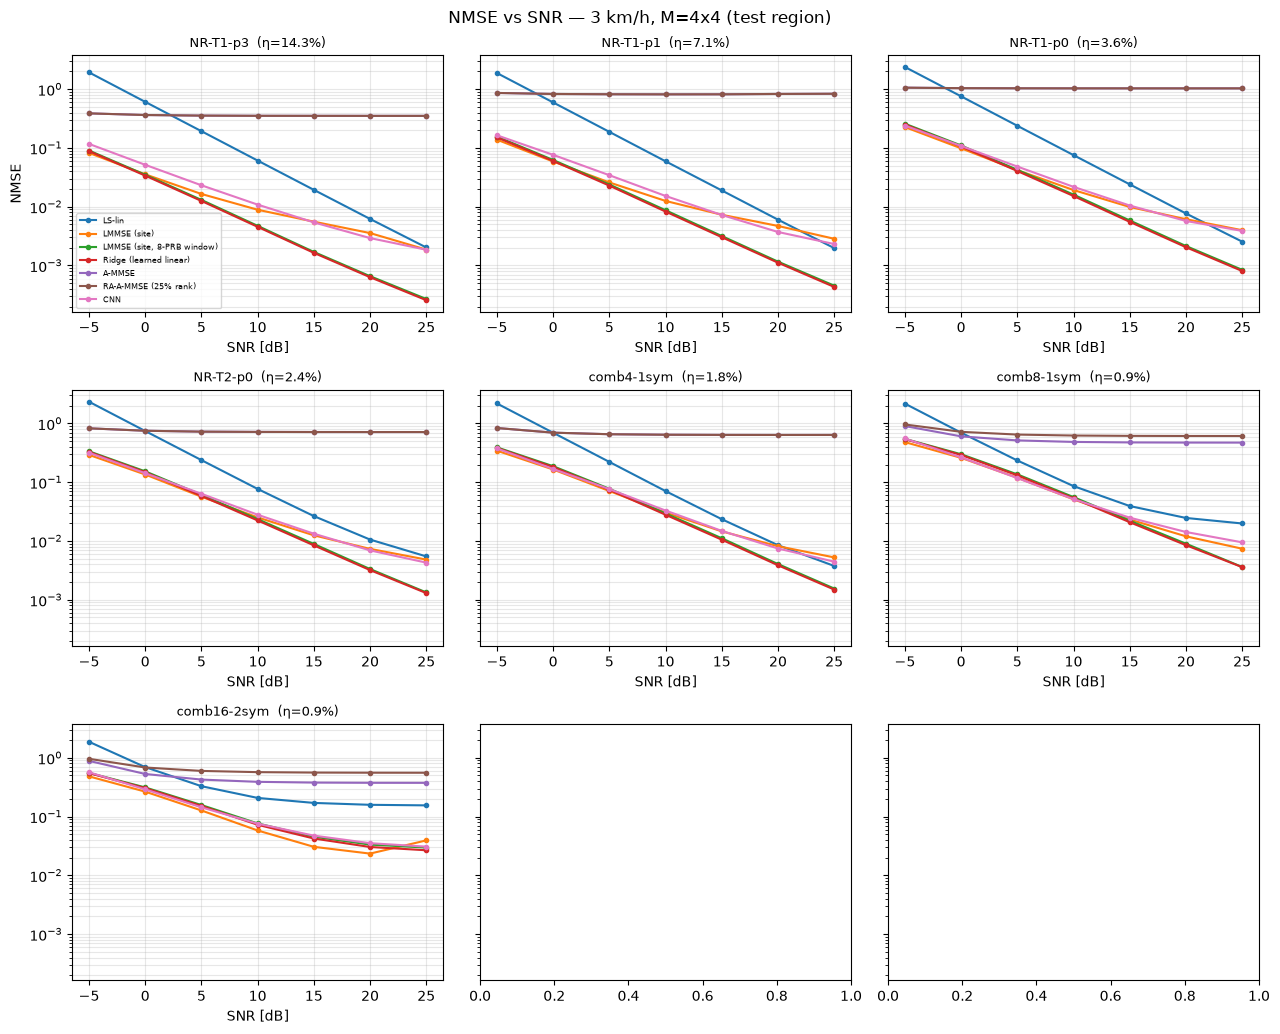

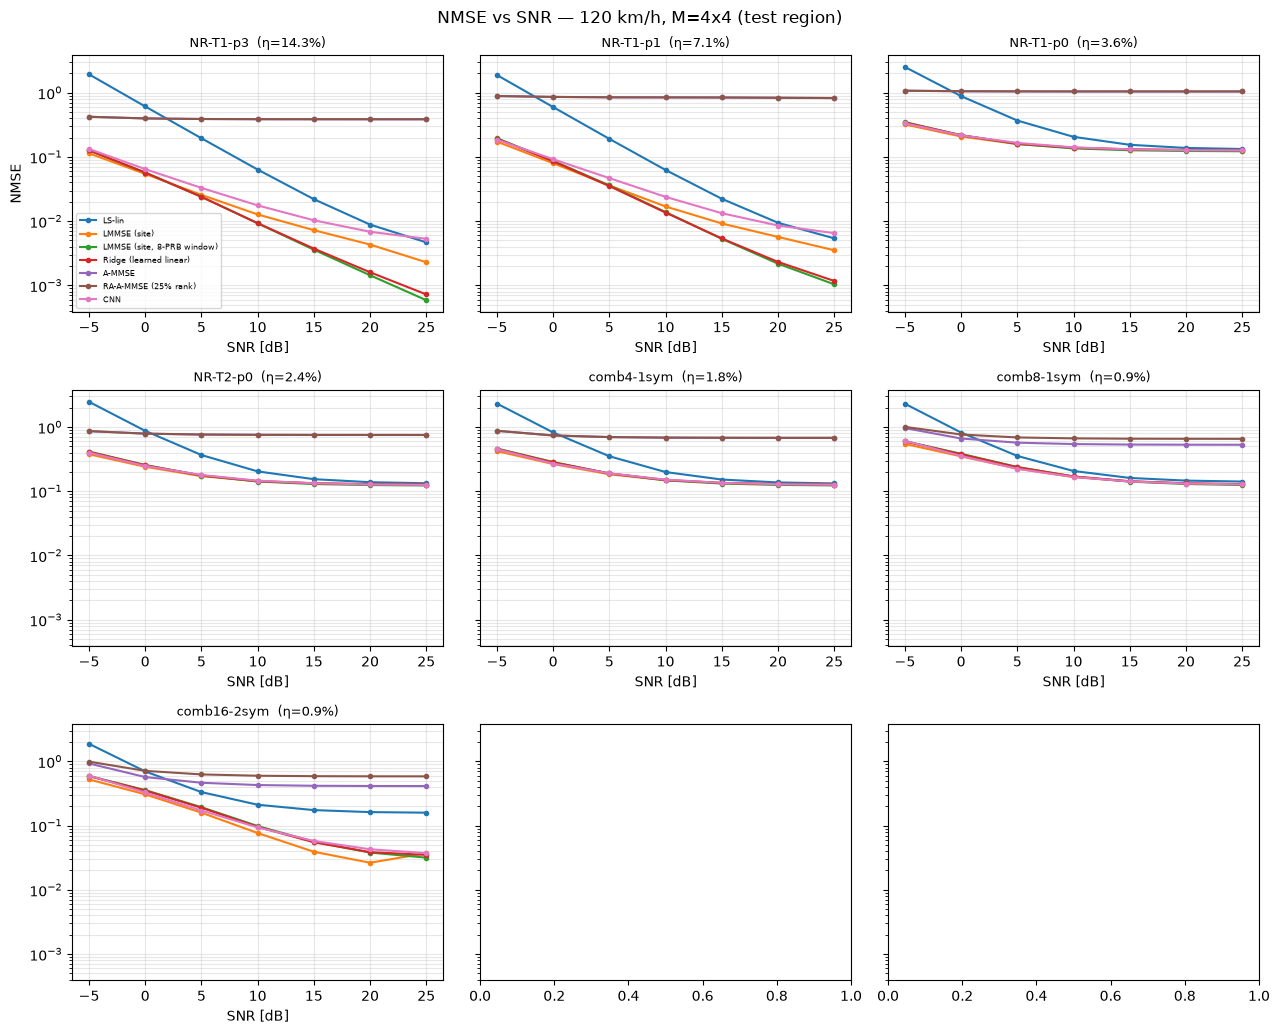

NMSE @15 dB [dB], 120 km/h (lower is better)
     config  LS-lin  LMMSE (site)  LMMSE (site, 8-PRB window)  Ridge (learned linear)  A-MMSE  RA-A-MMSE (25% rank)   CNN
   NR-T1-p3   -16.6         -21.4                       -24.4                   -24.3    -4.1                  -4.1 -19.9
   NR-T1-p1   -16.5         -20.4                       -22.7                   -22.7    -0.7                  -0.7 -18.8
   NR-T1-p0    -8.1          -8.8                        -9.0                    -8.8     0.2                   0.2  -8.8
   NR-T2-p0    -8.1          -8.8                        -8.9                    -8.8    -1.2                  -1.2  -8.8
 comb4-1sym    -8.2          -8.7                        -8.8                    -8.7    -1.7                  -1.7  -8.7
 comb8-1sym    -7.9          -8.5                        -8.5                    -8.4    -2.7                  -1.8  -8.5
comb16-2sym    -7.6         -14.1                       -12.5                   -12.6    -3.8        

In [ ]:
LEARNED = ["LS-lin", "LMMSE (site)", "LMMSE (site, 8-PRB window)", "Ridge (learned linear)", "A-MMSE", "RA-A-MMSE (25% rank)", "CNN"]
for v in (3, 120):
    plot_nmse(v, LEARNED, cfgs=[CFG[n] for n in LEARN_CONFIGS], ncols=3)

print("NMSE @15 dB [dB], 120 km/h (lower is better)")
print(pd.DataFrame([{"config": n, **{e: round(10 * np.log10(NMSE[(n, 120, e)][4]), 1) for e in LEARNED if (n, 120, e) in NMSE}} for n in LEARN_CONFIGS]).to_string(index=False))

In [ ]:
# [needs-torch]  complexity: parameters, FLOPs per slot, latency
def conv_flops(model):
    fl = 0
    for m in model.modules():
        if isinstance(m, nn.Conv2d): fl += 2 * m.in_channels * m.out_channels * 9 * NSYM * NSC
    return fl

def latency(fn, Hp, reps=5):
    fn(Hp, 0.01); t0 = time.perf_counter()
    for _ in range(reps): fn(Hp, 0.01)
    return (time.perf_counter() - t0) / reps / Hp.shape[0] * 1e3          # ms per (slot, antenna)

rows = []
for n in LEARN_CONFIGS:
    c = CFG[n]; L = len(c["Tp"]) * len(c["Fp_w"]); D = NSYM * WIN; nw = NSC // WIN
    Hp = pilots_of(Hte_v[120][:16], c)
    r = {"config": n, "L/window": L,
         "A-MMSE generator params (training only)": f"{sum(p.numel() for p in AMM_MODELS[n].parameters())/1e6:.1f}M",
         "stored filter [real params]": 2 * D * L,
         "FLOPs/slot filter": 8 * D * L * nw, "FLOPs/slot RA-25%": 8 * max(1, int(.25 * L)) * (L + D) * nw,
         "FLOPs/slot CNN": conv_flops(CNN_MODEL), "CNN params": sum(p.numel() for p in CNN_MODEL.parameters()),
         "ms LMMSE(Kron)": round(latency(lmmse("site", c, 120), Hp), 3),
         "ms linear filter": round(latency(window_filter_est(FILTERS[n]["ammse"], c, 120), Hp), 3),
         "ms CNN": round(latency(cnn_est(CNN_MODEL, c, 120), Hp), 3)}
    rows.append(r)
print(pd.DataFrame(rows).T.to_string(header=False))
print("\nA dense LMMSE filter recomputed every slot costs ~L^3 + 8*NM*L FLOPs; with cached filters it equals the A-MMSE matrix-vector product.")
print("Note: the paper's Table II lists A-MMSE as ~5.8 K FLOPs for L=72, N=72, M=14; 8*N*M*L is ~5.8e5, i.e. the table looks 100x off. Report your own counts.")

config                                     NR-T1-p3    NR-T1-p1    NR-T1-p0    NR-T2-p0  comb4-1sym  comb8-1sym  comb16-2sym
L/window                                        192          96          48          32          24          12           12
A-MMSE generator params (training only)       22.0M       22.0M       22.0M       22.0M       21.9M       21.9M        21.9M
stored filter [real params]                  516096      258048      129024       86016       64512       32256        32256
FLOPs/slot filter                           6193152     3096576     1548288     1032192      774144      387072       387072
FLOPs/slot RA-25%                           1769472      829440      400896      264192      196992       97632        97632
FLOPs/slot CNN                           2030966784  2030966784  2030966784  2030966784  2030966784  2030966784   2030966784
CNN params                                   252482      252482      252482      252482      252482      252482       252482


In [ ]:
# [needs-sionna, needs-torch]
from sionna.phy.nr import TBEncoder, TBDecoder, calculate_tb_size        # CHECK import path in 2.x
from sionna.phy.mapping import Mapper, Demapper, BinarySource

class Link:
    def __init__(self, cfg, qm=4, rate=0.5, seed=0):
        self.cfg, self.qm, self.rate = cfg, qm, rate
        rng = np.random.default_rng(seed + 1)
        px = np.exp(1j * (np.pi / 4 + np.pi / 2 * rng.integers(0, 4, (len(cfg["Tp"]), len(cfg["Fp"]))))).astype(np.complex64)   # unit-power QPSK DMRS
        self.px = torch.as_tensor(px, device=device)
        tbs = calculate_tb_size(modulation_order=qm, target_coderate=rate, num_prbs=N_PRB, num_ofdm_symbols=NSYM,
                                num_dmrs_per_prb=int(np.ceil(cfg["n_reserved"] / N_PRB)))[0]                                # CHECK: first output = TBS
        self.enc = TBEncoder(target_tb_size=tbs, num_coded_bits=cfg["n_data"] * qm, target_coderate=rate, num_bits_per_symbol=qm)
        self.dec = TBDecoder(self.enc, num_bp_iter=20)
        self.src, self.map, self.dem = BinarySource(), Mapper("qam", qm), Demapper("app", "qam", qm)
        self.tbs = int(self.enc.tb_size)
        self.didx = torch.as_tensor(np.flatnonzero(~cfg["reserved"].reshape(-1)), device=device)
        self.Tp, self.Fp = torch.as_tensor(cfg["Tp"], device=device), torch.as_tensor(cfg["Fp"], device=device)

    @torch.no_grad()
    def run_batch(self, H, snr_db, est_fn, err_var):
        """H: [B, A, 14, 288] complex64 torch. est_fn(Yp_ls[np], sig2) -> H_hat[np]; None = perfect CSI. Returns #block errors."""
        B = H.shape[0]; sig2 = 10 ** (-snr_db / 10)
        s = self.map(self.enc(self.src([B, self.tbs]))).to(torch.complex64)                  # [B, n_data]
        x = torch.zeros(B, NSYM * NSC, dtype=torch.complex64, device=device); x[:, self.didx] = s
        x = x.view(B, NSYM, NSC); x[:, self.Tp[:, None], self.Fp[None, :]] = self.px
        y = H * x[:, None] + torch.randn_like(H) * math.sqrt(sig2)
        if est_fn is None: Hh = H
        else:
            Yp = y[:, :, self.Tp][:, :, :, self.Fp] / self.px                                  # LS at pilots
            Hh = torch.as_tensor(est_fn(Yp.cpu().numpy(), sig2)).to(device)
        den = (Hh.abs() ** 2).sum(1).clamp_min(1e-9)
        z = (Hh.conj() * y).sum(1) / den; no = ((sig2 + err_var) / den).to(torch.float32)
        llr = self.dem(z.reshape(B, -1)[:, self.didx], no.reshape(B, -1)[:, self.didx]).reshape(B, -1)
        _, ok = self.dec(llr)
        return int((~ok.reshape(B).bool()).sum())

In [ ]:
# ---- estimator factory + validation-set error variances (numpy side) ----
ERRV = {}
def get_est(name, cfg, v):
    if name == "Perfect CSI": return None
    if name in ("LS-nn", "LS-lin"): return lambda Hp, s2: est_ls(Hp, cfg, name[3:])
    if name == "LMMSE (site)": return lmmse("site", cfg, v)
    if name == "LMMSE (TDL)": return lmmse("tdl", cfg, v)
    if name == "Ridge (learned linear)": return window_filter_est(FILTERS[cfg["name"]]["ridge"], cfg, v)
    if name == "A-MMSE": return window_filter_est(FILTERS[cfg["name"]]["ammse"], cfg, v)
    if name == "CNN": return cnn_est(CNN_MODEL, cfg, v)
    raise KeyError(name)

def err_var(name, cfg, v, snr):
    if name == "Perfect CSI": return 0.0
    key = (name, cfg["name"], v)
    if key not in ERRV: ERRV[key] = nmse_curve(Hva_v[v], cfg, get_est(name, cfg, v), reps=1)        # validation-region NMSE
    return float(ERRV[key][SNR_GRID.index(snr)])

In [ ]:
# [needs-sionna, needs-torch]  BLER sweep
LINK_CONFIGS = ["NR-T1-p3", "NR-T1-p1", "NR-T1-p0", "comb4-1sym", "comb8-1sym"]       # >= 1 custom comb; all trained in Step 7
LINK_SPEEDS  = [3, 120]
LINK_EST     = ["Perfect CSI", "LS-lin", "LMMSE (site)", "A-MMSE", "CNN"]
LINK_SNR     = [0, 5, 10, 15, 20, 25]
MAX_SLOTS, MIN_ERR, BATCH = 3000, 100, 50            # lower MAX_SLOTS on CPU
BLER, TBS = {}, {}
Hte_t = {v: torch.as_tensor(Hte_v[v]).to(device) for v in SPEEDS}
_rng = np.random.default_rng(7)

def run_link_sweep(cfgs=LINK_CONFIGS, speeds=LINK_SPEEDS, ests=LINK_EST, snrs=LINK_SNR):
    t0 = time.time()
    for cn in cfgs:
        link = Link(CFG[cn]); TBS[cn] = link.tbs
        for v in speeds:
            for e in ests:
                fn = get_est(e, CFG[cn], v); out = []
                for snr in snrs:
                    ev = err_var(e, CFG[cn], v, snr); errs = n = 0
                    while n < MAX_SLOTS and errs < MIN_ERR:
                        errs += link.run_batch(Hte_t[v][torch.as_tensor(_rng.integers(0, len(Hte_t[v]), BATCH), device=device)], snr, fn, ev); n += BATCH
                    out.append(errs / n)
                BLER[(e, cn, v)] = np.array(out)
                print(f"{cn:12s} {v:>3} km/h {e:14s} TBS={link.tbs} BLER={np.round(out, 3)}  [{time.time()-t0:.0f}s]")
run_link_sweep()
torch.save(dict(BLER=BLER, TBS=TBS), "link_results.pt")

NR-T1-p3       3 km/h Perfect CSI    TBS=6912 BLER=[0. 0. 0. 0. 0. 0.]  [98s]
NR-T1-p3       3 km/h LS-lin         TBS=6912 BLER=[1. 0. 0. 0. 0. 0.]  [190s]
NR-T1-p3       3 km/h LMMSE (site)   TBS=6912 BLER=[0. 0. 0. 0. 0. 0.]  [367s]
NR-T1-p3       3 km/h A-MMSE         TBS=6912 BLER=[0.61  0.575 0.605 0.575 0.58  0.54 ]  [375s]
NR-T1-p3       3 km/h CNN            TBS=6912 BLER=[0. 0. 0. 0. 0. 0.]  [823s]
NR-T1-p3     120 km/h Perfect CSI    TBS=6912 BLER=[0. 0. 0. 0. 0. 0.]  [919s]
NR-T1-p3     120 km/h LS-lin         TBS=6912 BLER=[1. 0. 0. 0. 0. 0.]  [1011s]
NR-T1-p3     120 km/h LMMSE (site)   TBS=6912 BLER=[0.027 0.    0.    0.    0.    0.   ]  [1174s]
NR-T1-p3     120 km/h A-MMSE         TBS=6912 BLER=[0.76  0.753 0.733 0.693 0.74  0.687]  [1180s]
NR-T1-p3     120 km/h CNN            TBS=6912 BLER=[0. 0. 0. 0. 0. 0.]  [1628s]
NR-T1-p1       3 km/h Perfect CSI    TBS=7424 BLER=[0. 0. 0. 0. 0. 0.]  [1734s]
NR-T1-p1       3 km/h LS-lin         TBS=7424 BLER=[1. 0. 0. 0. 0. 0.]  [

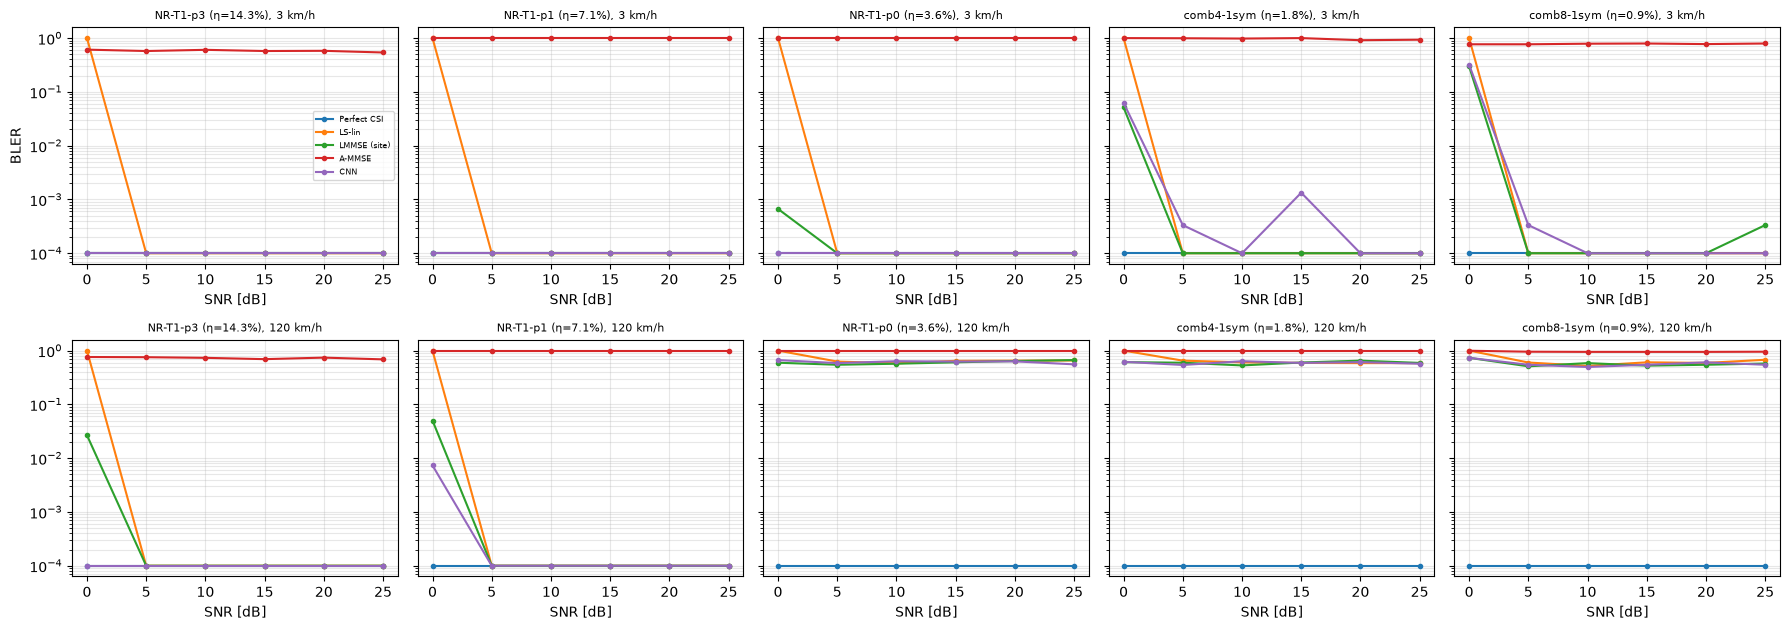

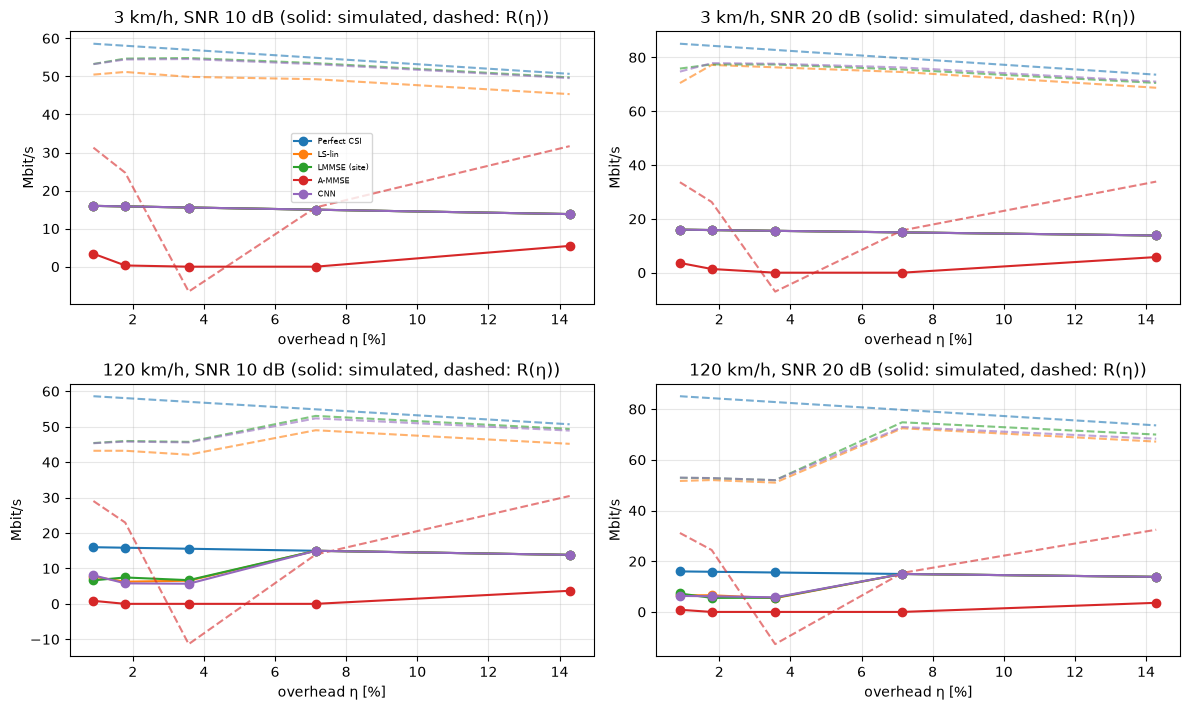

 speed  SNR    estimator  η* goodput_RE [%]  η* goodput_TBS [%]  η* R(η) [%]
     3   10  Perfect CSI               0.89                0.89         0.89
     3   10       LS-lin               0.89                0.89         1.79
     3   10 LMMSE (site)               0.89                0.89         3.57
     3   10       A-MMSE              14.29               14.29        14.29
     3   10          CNN               0.89                0.89         3.57
     3   20  Perfect CSI               0.89                0.89         0.89
     3   20       LS-lin               0.89                0.89         1.79
     3   20 LMMSE (site)               0.89                0.89         1.79
     3   20       A-MMSE              14.29               14.29        14.29
     3   20          CNN               0.89                0.89         1.79
   120   10  Perfect CSI               0.89                0.89         0.89
   120   10       LS-lin               7.14                7.14         7.14

In [ ]:
# ---- BLER / goodput / R(eta) / eta* (numpy) ----
QM, RATE = 4, 0.5
def goodput_tbs(cn, e, v):  return TBS[cn] * (1 - BLER[(e, cn, v)]) / T_SLOT / 1e6                          # Mbit/s (NR TBS)
def goodput_re(cn, e, v):   return QM * RATE * CFG[cn]["n_data"] * (1 - BLER[(e, cn, v)]) / T_SLOT / 1e6   # Mbit/s (data-RE based)
def rate_bound(cn, e, v, snr, A):
    """R(eta) = (1-eta) log2(1 + rho ||h_hat||^2 / (1 + rho sigma_e^2)),  ||h_hat||^2 = A (1 - NMSE)   [bit / RE]."""
    nm = 0.0 if e == "Perfect CSI" else float(NMSE[(cn, v, e)][SNR_GRID.index(snr)])
    rho = 10 ** (snr / 10)
    return (1 - CFG[cn]["eta"]) * np.log2(1 + rho * A * (1 - nm) / (1 + rho * nm))
to_mbps = lambda bit_per_re: bit_per_re * NSYM * NSC / T_SLOT / 1e6

def plot_bler():
    fig, axs = plt.subplots(len(LINK_SPEEDS), len(LINK_CONFIGS), figsize=(3.6 * len(LINK_CONFIGS), 3.2 * len(LINK_SPEEDS)), sharey=True, squeeze=False)
    for i, v in enumerate(LINK_SPEEDS):
        for j, cn in enumerate(LINK_CONFIGS):
            for e in LINK_EST:
                if (e, cn, v) in BLER: axs[i, j].semilogy(LINK_SNR, np.maximum(BLER[(e, cn, v)], 1e-4), marker="o", ms=3, label=e)
            axs[i, j].set_title(f"{cn} (η={100*CFG[cn]['eta']:.1f}%), {v} km/h", fontsize=8); axs[i, j].grid(alpha=.3, which="both"); axs[i, j].set_xlabel("SNR [dB]")
    axs[0, 0].set_ylabel("BLER"); axs[0, 0].legend(fontsize=6); plt.tight_layout(); plt.show()

def plot_goodput_vs_eta(snrs=(10, 20)):
    """solid: simulated goodput on data REs; dashed: information-theoretic R(eta) with the measured NMSE (same units)."""
    A = M_EVAL ** 2; cs = sorted(LINK_CONFIGS, key=lambda c: CFG[c]["eta"]); et = [100 * CFG[c]["eta"] for c in cs]
    fig, axs = plt.subplots(len(LINK_SPEEDS), len(snrs), figsize=(6 * len(snrs), 3.6 * len(LINK_SPEEDS)), squeeze=False)
    rows = []
    for i, v in enumerate(LINK_SPEEDS):
        for j, snr in enumerate(snrs):
            k = LINK_SNR.index(snr); ax = axs[i, j]
            for e in LINK_EST:
                ge = {c: goodput_re(c, e, v)[k] for c in cs}; gt = {c: goodput_tbs(c, e, v)[k] for c in cs}
                r = {c: rate_bound(c, e, v, snr, A) for c in cs}
                line, = ax.plot(et, [ge[c] for c in cs], marker="o", label=e); ax.plot(et, [to_mbps(r[c]) for c in cs], "--", color=line.get_color(), alpha=.6)
                pick = lambda d: round(100 * CFG[max(d, key=lambda c: (round(d[c], 6), -CFG[c]["eta"]))]["eta"], 2)      # ties -> smaller eta
                rows.append(dict(speed=v, SNR=snr, estimator=e, **{"η* goodput_RE [%]": pick(ge), "η* goodput_TBS [%]": pick(gt), "η* R(η) [%]": pick(r)}))
            ax.set_title(f"{v} km/h, SNR {snr} dB (solid: simulated, dashed: R(η))"); ax.set_xlabel("overhead η [%]"); ax.set_ylabel("Mbit/s"); ax.grid(alpha=.3)
    axs[0, 0].legend(fontsize=6); plt.tight_layout(); plt.show()
    return pd.DataFrame(rows)

plot_bler()
ETA_STAR = plot_goodput_vs_eta()
print(ETA_STAR.to_string(index=False))
print("\nGoodput @ 15 dB, 120 km/h [Mbit/s]: NR-TBS based vs data-RE based")
print(pd.DataFrame([{"config": c, "η[%]": round(100 * CFG[c]["eta"], 2), "TBS": TBS[c], **{f"{e} TBS": round(goodput_tbs(c, e, 120)[LINK_SNR.index(15)], 2) for e in LINK_EST[1:]},
                     **{f"{e} RE": round(goodput_re(c, e, 120)[LINK_SNR.index(15)], 2) for e in LINK_EST[1:]}} for c in LINK_CONFIGS]).to_string(index=False))

In [ ]:
# [needs-sionna, needs-torch]  (a) How much overhead can each estimator save at BLER <= 10 % ?
RED_CONFIGS = ["NR-T1-p3", "NR-T1-p1", "NR-T1-p0", "comb4-1sym", "comb8-1sym", "comb16-2sym"]   # all trained in Step 7
SNR_T, BLER_T = 15, 0.10
run_link_sweep(cfgs=[c for c in RED_CONFIGS if c not in LINK_CONFIGS], speeds=LINK_SPEEDS, ests=LINK_EST, snrs=LINK_SNR)   # fills BLER for the new configs

def eta_min_table(snr=SNR_T, target=BLER_T):
    k = LINK_SNR.index(snr); rows = []
    for v in LINK_SPEEDS:
        for e in LINK_EST:
            ok = [c for c in RED_CONFIGS if (e, c, v) in BLER and BLER[(e, c, v)][k] <= target]
            best = min(ok, key=lambda c: CFG[c]["eta"]) if ok else None
            rows.append({"speed": v, "estimator": e, "smallest config with BLER<=10%": best, "η_min [%]": round(100 * CFG[best]["eta"], 2) if best else None,
                         **{c: round(float(BLER[(e, c, v)][k]), 3) for c in RED_CONFIGS if (e, c, v) in BLER}})
    return pd.DataFrame(rows)
ETA_MIN = eta_min_table(); print(f"BLER at {SNR_T} dB; target {BLER_T}"); print(ETA_MIN.to_string(index=False))

comb16-2sym    3 km/h Perfect CSI    TBS=7424 BLER=[0. 0. 0. 0. 0. 0.]  [122s]
comb16-2sym    3 km/h LS-lin         TBS=7424 BLER=[0.96  0.383 0.34  0.294 0.314 0.294]  [135s]
comb16-2sym    3 km/h LMMSE (site)   TBS=7424 BLER=[0.291 0.    0.    0.    0.    0.008]  [246s]
comb16-2sym    3 km/h A-MMSE         TBS=7424 BLER=[0.733 0.585 0.61  0.585 0.6   0.615]  [254s]
comb16-2sym    3 km/h CNN            TBS=7424 BLER=[0.428 0.008 0.    0.    0.    0.   ]  [654s]
comb16-2sym  120 km/h Perfect CSI    TBS=7424 BLER=[0. 0. 0. 0. 0. 0.]  [774s]
comb16-2sym  120 km/h LS-lin         TBS=7424 BLER=[0.987 0.4   0.285 0.357 0.34  0.337]  [787s]
comb16-2sym  120 km/h LMMSE (site)   TBS=7424 BLER=[0.427 0.012 0.    0.    0.    0.005]  [897s]
comb16-2sym  120 km/h A-MMSE         TBS=7424 BLER=[0.793 0.76  0.72  0.66  0.747 0.673]  [904s]
comb16-2sym  120 km/h CNN            TBS=7424 BLER=[0.444 0.078 0.002 0.    0.    0.   ]  [1260s]
BLER at 15 dB; target 0.1
 speed    estimator smallest config wit

In [ ]:
# [needs-torch]  (b) speed mismatch:  train/design at 3 km/h -> test at 120 km/h and vice versa.  NMSE @ 15 dB.
CFG_MM, SNR_MM = "NR-T1-p0", 15              # reduced-pilot configuration where classical estimators struggle at 120 km/h
STEPS_MM = 2000

def mismatch_speed(cfg_name=CFG_MM, snr=SNR_MM):
    c, k, rows = CFG[cfg_name], SNR_GRID.index(snr), []
    db = lambda x: round(10 * np.log10(x), 2)
    for tr_v, te_v in ((3, 120), (120, 3)):
        r = {"train→test": f"{tr_v}→{te_v} km/h"}
        r["LMMSE matched"] = db(NMSE[(cfg_name, te_v, "LMMSE (site)")][k])
        r["LMMSE mismatched (R_t of train speed)"] = db(nmse_curve(Hte_v[te_v], c, lmmse("site", c, te_v, Rt_from=tr_v))[k])
        Wr = fit_all_ridge(c, speeds=[tr_v])
        r["Ridge matched"] = db(NMSE[(cfg_name, te_v, "Ridge (learned linear)")][k])
        r["Ridge mismatched"] = db(nmse_curve(Hte_v[te_v], c, window_filter_est(Wr, c, tr_v))[k])
        _, Wa = train_ammse(c, steps=STEPS_MM, train_speeds=[tr_v], val_every=STEPS_MM)
        r["A-MMSE matched"] = db(NMSE[(cfg_name, te_v, "A-MMSE")][k])
        r["A-MMSE mismatched"] = db(nmse_curve(Hte_v[te_v], c, window_filter_est(Wa, c, tr_v))[k])
        cn = train_cnn([c], steps=STEPS_MM * 2, train_speeds=[tr_v], val_every=STEPS_MM * 2)
        r["CNN matched"] = db(NMSE[(cfg_name, te_v, "CNN")][k])
        r["CNN mismatched"] = db(nmse_curve(Hte_v[te_v], c, cnn_est(cn, c, tr_v))[k])
        rows.append(r)
    return pd.DataFrame(rows).set_index("train→test").T

MM = mismatch_speed(); print(f"NMSE [dB] @ {SNR_MM} dB, config {CFG_MM}"); print(MM.to_string())
print("\nDegradation (mismatched - matched) [dB]:")
for m in ("LMMSE", "Ridge", "A-MMSE", "CNN"):
    a = [c for c in MM.index if c.startswith(m) and "mismatched" in c][0]; b = [c for c in MM.index if c.startswith(m) and "matched" in c and "mis" not in c][0]
    print(f"  {m:7s}", (MM.loc[a] - MM.loc[b]).round(2).to_dict())

  [NR-T1-p0] step  2000  train NMSE  -3.11 dB | val (mean over SNR/speed)  -1.97 dB
  [CNN] step  4000  train -13.70 dB | val -18.17 dB
  [NR-T1-p0] step  2000  train NMSE  -2.65 dB | val (mean over SNR/speed)  -1.81 dB
  [CNN] step  4000  train  -8.41 dB | val  -8.25 dB
NMSE [dB] @ 15 dB, config NR-T1-p0
train→test                             3→120 km/h  120→3 km/h
LMMSE matched                               -8.85      -20.05
LMMSE mismatched (R_t of train speed)       -8.57      -17.01
Ridge matched                               -8.82      -22.58
Ridge mismatched                            -8.68      -17.15
A-MMSE matched                               0.19        0.13
A-MMSE mismatched                           -3.30       -3.79
CNN matched                                 -8.82      -19.80
CNN mismatched                              -8.70      -12.61

Degradation (mismatched - matched) [dB]:
  LMMSE   {'3→120 km/h': 0.28, '120→3 km/h': 3.04}
  Ridge   {'3→120 km/h': 0.14, '120→3 km/h

In [ ]:
# [needs-torch]  (c) site mismatch: models/covariances from site A applied to a second site B.
# Build site B by moving the BS (and/or the UE region) in Steps 2-3, then:
#     dsB = generate_dataset(scene, outdoor_positions_B, splits_B, loc_dirs_B, bs_pos_B)
# Everything below uses estimators trained ONLY on site A.
def mismatch_site(dsB, cfg_name=CFG_MM, snr=SNR_MM, speeds=(3, 120)):
    c, k, rows = CFG[cfg_name], SNR_GRID.index(snr), []
    db = lambda x: round(10 * np.log10(x), 2)
    for v in speeds:
        HB = subarray(dsB["H"][(dsB["speed"] == v) & (dsB["dir_id"] == 0)], M_EVAL)
        RfB, RtB = estimate_cov(HB)
        ests = {"LMMSE (site A cov.)": lmmse("site", c, v), "LMMSE (oracle: site B cov.)": (lambda f: (lambda Hp, s2: f(Hp, s2)))(SepLMMSE(RfB, RtB, c["Tp"], c["Fp"])),
                "LMMSE (TDL)": lmmse("tdl", c, v), "Ridge (site A)": get_est("Ridge (learned linear)", c, v),
                "A-MMSE (site A)": get_est("A-MMSE", c, v), "CNN (site A)": get_est("CNN", c, v)}
        r = {"speed": v}; r.update({n: db(nmse_curve(HB, c, f)[k]) for n, f in ests.items()}); rows.append(r)
    return pd.DataFrame(rows).set_index("speed").T
if "dsB" in globals(): print(mismatch_site(dsB).to_string())
else: print("dsB not defined yet: generate the second-site dataset first.")

dsB not defined yet: generate the second-site dataset first.
